In [10]:
# Load the four previously created datasets
imperviousness_df = pd.read_csv("merged_complete_datasets/imperviousness_by_lor.csv")
population_df = pd.read_csv("merged_complete_datasets/berlin_neighbourhood_environment_population.csv")
tree_cover_df = pd.read_csv("merged_complete_datasets/tree_cover_comparison.csv")
land_cover_df = pd.read_csv("merged_complete_datasets/berlin_land_cover_by_neighbourhood.csv")

# Inspect their dimensions and column names
datasets = {
    "Imperviousness": imperviousness_df,
    "Population": population_df,
    "Tree cover": tree_cover_df,
    "Land cover": land_cover_df
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


--- Imperviousness ---
Shape: (143, 7)
Columns: ['bzr_id', 'bzr_name', 'bez', 'imperviousness_mean', 'imperviousness_median', 'impervious_pixels_pct', 'pixel_count']


,bzr_id,bzr_name,bez,imperviousness_mean,imperviousness_median,impervious_pixels_pct,pixel_count
0,11001,Tiergarten Süd,01 - Mitte,40.069335,0.0,48.743233,51720
1,11002,Regierungsviertel,01 - Mitte,89.484086,100.0,95.363158,26958
2,11003,Alexanderplatz,01 - Mitte,74.750883,93.0,84.473735,62288



--- Population ---
Shape: (143, 15)
Columns: ['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', 'area_km2', 'population_density_km2']


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural,population_2025,male_population_2025,female_population_2025,population_complete,area_km2,population_density_km2
0,11001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720,40.069335,48.496369,16349.0,8584.0,7765.0,True,5.172416,3160.805245
1,11002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958,89.484086,4.922988,13758.0,7056.0,6702.0,True,2.695472,5104.114961
2,11003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288,74.750883,4.914470,62409.0,31711.0,30698.0,True,6.228747,10019.510868



--- Tree cover ---
Shape: (143, 9)
Columns: ['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural']


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural
0,11001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720,40.069335,48.496369
1,11002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958,89.484086,4.922988
2,11003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288,74.750883,4.914470



--- Land cover ---
Shape: (143, 16)
Columns: ['bzr_id', 'bzr_name', 'bez', 'urban_fabric', 'green_natural', 'industrial_commercial', 'transport_infrastructure', 'water_wetlands', 'Arable land (annual crops)', 'Complex and mixed cultivation patterns', 'Construction sites', 'Isolated structures', 'Land without current use', 'Mineral extraction and dump sites', 'Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)', 'Sports and leisure facilities']


,bzr_id,bzr_name,bez,urban_fabric,green_natural,industrial_commercial,transport_infrastructure,water_wetlands,Arable land (annual crops),Complex and mixed cultivation patterns,Construction sites,Isolated structures,Land without current use,Mineral extraction and dump sites,"Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)",Sports and leisure facilities
0,11001,Tiergarten Süd,01 - Mitte,16.578038,48.496369,22.201399,9.591352,3.132842,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,11002,Regierungsviertel,01 - Mitte,37.358698,4.922988,40.585440,14.506333,1.967732,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.658809
2,11003,Alexanderplatz,01 - Mitte,38.662168,4.914470,35.587205,14.512580,5.733040,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.590537


In [11]:
# Validate the main urban exposure dataset
urban_df = population_df.copy()

# Check number of neighbourhoods and unique identifiers
print("Total records:", len(urban_df))
print("Unique Bezirksregion IDs:", urban_df["bzr_id"].nunique())
print("Duplicate IDs:", urban_df["bzr_id"].duplicated().sum())

# Check missing values
print("\nMissing values:")
print(
    urban_df[
        [
            "population_2025",
            "population_density_km2",
            "imperviousness_mean",
            "tree_cover_mean",
            "green_natural"
        ]
    ].isna().sum()
)

# Check population completeness
print("\nPopulation completeness:")
print(urban_df["population_complete"].value_counts(dropna=False))

# Review indicator distributions
indicators = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

print("\nIndicator descriptive statistics:")
print(urban_df[indicators].describe().round(2))

Total records: 143
Unique Bezirksregion IDs: 143
Duplicate IDs: 0

Missing values:
population_2025           2
population_density_km2    2
imperviousness_mean       0
tree_cover_mean           0
green_natural             0
dtype: int64

Population completeness:
population_complete
True     141
False      2
Name: count, dtype: int64

Indicator descriptive statistics:
       population_density_km2  imperviousness_mean  tree_cover_mean  \
count                  141.00               143.00           143.00   
mean                  8111.11                44.64            17.26   
std                   6223.02                19.17            15.35   
min                    264.49                 4.26             0.75   
25%                   3392.34                34.01             7.13   
50%                   6168.44                44.73            12.08   
75%                  12273.26                59.78            20.34   
max                  32100.38                89.48            6

In [13]:
# Check the available columns in each dataset
for name, df in {
    "urban_df": urban_df,
    "imperviousness_df": imperviousness_df,
    "tree_cover_df": tree_cover_df,
    "land_cover_df": land_cover_df
}.items():
    print(f"\n{name}:")
    print(df.columns.tolist())


urban_df:
['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', 'area_km2', 'population_density_km2']

imperviousness_df:
['bzr_id', 'bzr_name', 'bez', 'imperviousness_mean', 'imperviousness_median', 'impervious_pixels_pct', 'pixel_count']

tree_cover_df:
['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural']

land_cover_df:
['bzr_id', 'bzr_name', 'bez', 'urban_fabric', 'green_natural', 'industrial_commercial', 'transport_infrastructure', 'water_wetlands', 'Arable land (annual crops)', 'Complex and mixed cultivation patterns', 'Construction sites', 'Isolated structures', 'Land without current use', 'Mineral extraction and dump sites', 'Open spaces with little or no vegetation (beaches, dunes, bare rocks, gl

In [14]:
# Compare alternative imperviousness indicators
print("Imperviousness indicators:")
print(
    imperviousness_df[
        ["imperviousness_mean", "imperviousness_median", "impervious_pixels_pct"]
    ].describe().round(2)
)

# Compare alternative tree-cover indicators
print("\nTree-cover indicators:")
print(
    tree_cover_df[
        ["tree_cover_mean", "tree_cover_median", "tree_cover_pixels_pct"]
    ].describe().round(2)
)

# Check correlations between the alternative measures
print("\nImperviousness correlations:")
print(
    imperviousness_df[
        ["imperviousness_mean", "imperviousness_median", "impervious_pixels_pct"]
    ].corr().round(3)
)

print("\nTree-cover correlations:")
print(
    tree_cover_df[
        ["tree_cover_mean", "tree_cover_median", "tree_cover_pixels_pct"]
    ].corr().round(3)
)

Imperviousness indicators:
       imperviousness_mean  imperviousness_median  impervious_pixels_pct
count               143.00                 143.00                 143.00
mean                 44.64                  46.79                  60.42
std                  19.17                  31.26                  20.26
min                   4.26                   0.00                   9.05
25%                  34.01                  18.00                  51.07
50%                  44.73                  52.00                  63.95
75%                  59.78                  74.25                  74.82
max                  89.48                 100.00                  95.36

Tree-cover indicators:
       tree_cover_mean  tree_cover_median  tree_cover_pixels_pct
count           143.00             143.00                 143.00
mean             17.26               8.16                  21.12
std              15.35              25.03                  16.56
min               0.75          

In [15]:
# Calculate correlations between the selected urban indicators
selected_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

correlation_matrix = urban_df[selected_cols].corr(method="spearman")

print("Spearman correlation matrix:")
print(correlation_matrix.round(3))

Spearman correlation matrix:
                        population_density_km2  imperviousness_mean  \
population_density_km2                   1.000                0.802   
imperviousness_mean                      0.802                1.000   
tree_cover_mean                         -0.580               -0.788   
green_natural                           -0.520               -0.711   

                        tree_cover_mean  green_natural  
population_density_km2           -0.580         -0.520  
imperviousness_mean              -0.788         -0.711  
tree_cover_mean                   1.000          0.849  
green_natural                     0.849          1.000  


In [16]:
# Calculate lower and upper quartile thresholds
indicators = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

quartile_thresholds = urban_df[indicators].quantile([0.25, 0.50, 0.75]).T

quartile_thresholds.columns = ["Q1_25%", "Median_50%", "Q3_75%"]

print("Neighbourhood indicator thresholds:")
print(quartile_thresholds.round(2))

Neighbourhood indicator thresholds:
                         Q1_25%  Median_50%    Q3_75%
population_density_km2  3392.34     6168.44  12273.26
imperviousness_mean       34.01       44.73     59.78
tree_cover_mean            7.13       12.08     20.34
green_natural              5.18       11.78     25.18


In [17]:
# Assign relative quartile groups to each neighbourhood
for col in indicators:
    q1 = urban_df[col].quantile(0.25)
    q3 = urban_df[col].quantile(0.75)

    urban_df[f"{col}_group"] = "Middle"

    urban_df.loc[urban_df[col] <= q1, f"{col}_group"] = "Lower quartile"
    urban_df.loc[urban_df[col] >= q3, f"{col}_group"] = "Upper quartile"

    urban_df.loc[urban_df[col].isna(), f"{col}_group"] = "Missing"

# Count neighbourhoods in each group
for col in indicators:
    print(f"\n{col}:")
    print(urban_df[f"{col}_group"].value_counts())


population_density_km2:
population_density_km2_group
Middle            69
Lower quartile    36
Upper quartile    36
Missing            2
Name: count, dtype: int64

imperviousness_mean:
imperviousness_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

tree_cover_mean:
tree_cover_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

green_natural:
green_natural_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64


In [18]:
# Assign relative quartile groups to each neighbourhood
for col in indicators:
    q1 = urban_df[col].quantile(0.25)
    q3 = urban_df[col].quantile(0.75)

    urban_df[f"{col}_group"] = "Middle"

    urban_df.loc[urban_df[col] <= q1, f"{col}_group"] = "Lower quartile"
    urban_df.loc[urban_df[col] >= q3, f"{col}_group"] = "Upper quartile"

    urban_df.loc[urban_df[col].isna(), f"{col}_group"] = "Missing"

# Count neighbourhoods in each group
for col in indicators:
    print(f"\n{col}:")
    print(urban_df[f"{col}_group"].value_counts())


population_density_km2:
population_density_km2_group
Middle            69
Lower quartile    36
Upper quartile    36
Missing            2
Name: count, dtype: int64

imperviousness_mean:
imperviousness_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

tree_cover_mean:
tree_cover_mean_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64

green_natural:
green_natural_group
Middle            71
Upper quartile    36
Lower quartile    36
Name: count, dtype: int64


In [19]:
# Identify neighbourhoods in the upper quartile for both indicators
high_density_high_impervious = urban_df[
    (urban_df["population_density_km2_group"] == "Upper quartile") &
    (urban_df["imperviousness_mean_group"] == "Upper quartile")
].copy()

# Display the selected neighbourhoods
profile_cols = [
    "bzr_name",
    "bez",
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

high_density_high_impervious = high_density_high_impervious.sort_values(
    "population_density_km2",
    ascending=False
)

print("Neighbourhoods with high population density and high imperviousness:")
print(high_density_high_impervious[profile_cols].round(2).to_string(index=False))

print(
    "\nNumber of neighbourhoods:",
    len(high_density_high_impervious)
)

Neighbourhoods with high population density and high imperviousness:
                  bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
            Helmholtzplatz                     03 - Pankow                32100.38                85.86             1.64           3.12
              Reuterstraße                   08 - Neukölln                26674.50                75.53             3.28           1.64
    Frankfurter Allee Nord   02 - Friedrichshain-Kreuzberg                24361.54                78.03             2.85           2.64
           Wedding Zentrum                      01 - Mitte                22515.30                70.51             6.45           7.29
       Prenzlauer Berg Süd                     03 - Pankow                20316.37                66.60            10.19          16.52
   Prenzlauer Berg Südwest                     03 - Pankow                19804.45                77.48            

In [20]:
# Check greenery indicators within the 25 selected neighbourhoods
high_density_high_impervious["low_tree_cover"] = (
    high_density_high_impervious["tree_cover_mean_group"] == "Lower quartile"
)

high_density_high_impervious["low_green_natural"] = (
    high_density_high_impervious["green_natural_group"] == "Lower quartile"
)

high_density_high_impervious["low_both_green_indicators"] = (
    high_density_high_impervious["low_tree_cover"] &
    high_density_high_impervious["low_green_natural"]
)

print("Greenery profile among the 25 neighbourhoods:")
print(
    high_density_high_impervious[
        ["low_tree_cover", "low_green_natural", "low_both_green_indicators"]
    ].sum()
)

print("\nNeighbourhoods in the lower quartile for both greenery indicators:")
print(
    high_density_high_impervious.loc[
        high_density_high_impervious["low_both_green_indicators"],
        ["bzr_name", "bez", "population_density_km2",
         "imperviousness_mean", "tree_cover_mean", "green_natural"]
    ].round(2).to_string(index=False)
)

Greenery profile among the 25 neighbourhoods:
low_tree_cover               18
low_green_natural            12
low_both_green_indicators    12
dtype: int64

Neighbourhoods in the lower quartile for both greenery indicators:
                  bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
            Helmholtzplatz                     03 - Pankow                32100.38                85.86             1.64           3.12
              Reuterstraße                   08 - Neukölln                26674.50                75.53             3.28           1.64
    Frankfurter Allee Nord   02 - Friedrichshain-Kreuzberg                24361.54                78.03             2.85           2.64
                   Rixdorf                   08 - Neukölln                18920.39                67.69             4.48           3.84
            Friedenau West       07 - Tempelhof-Schöneberg                18187.19               

In [21]:
# Separate the 25 neighbourhoods into two greenery profiles
lower_greenery = high_density_high_impervious[
    high_density_high_impervious["low_both_green_indicators"]
].copy()

other_greenery = high_density_high_impervious[
    ~high_density_high_impervious["low_both_green_indicators"]
].copy()

# Compare the two groups
comparison = pd.DataFrame({
    "Lower greenery (12)": lower_greenery[
        ["tree_cover_mean", "green_natural"]
    ].median(),
    "Other greenery (13)": other_greenery[
        ["tree_cover_mean", "green_natural"]
    ].median()
})

print("Median greenery indicators by profile:")
print(comparison.round(2))

print("\nThe 13 neighbourhoods outside the lower quartile for both indicators:")
print(
    other_greenery[
        ["bzr_name", "bez", "population_density_km2",
         "imperviousness_mean", "tree_cover_mean", "green_natural"]
    ].sort_values("tree_cover_mean", ascending=False)
    .round(2)
    .to_string(index=False)
)

Median greenery indicators by profile:
                 Lower greenery (12)  Other greenery (13)
tree_cover_mean                 3.01                 7.51
green_natural                   3.03                 9.58

The 13 neighbourhoods outside the lower quartile for both indicators:
                bzr_name                             bez  population_density_km2  imperviousness_mean  tree_cover_mean  green_natural
    Tempelhofer Vorstadt   02 - Friedrichshain-Kreuzberg                13472.36                61.25            10.74          16.48
      Schöneberg Nordost       07 - Tempelhof-Schöneberg                17804.13                62.69            10.27           9.88
     Prenzlauer Berg Süd                     03 - Pankow                20316.37                66.60            10.19          16.52
Südliche  Friedrichstadt   02 - Friedrichshain-Kreuzberg                14011.44                63.81             8.53           9.58
   Volkspark Wilmersdorf 04 - Charlottenburg-W

lower greenery: Neighbourhood in the above 25 classification that fell into the lower quartile for tree cover mean (mean percentage of land covered with threes) and green natural.

Other_greenery - all neighbourhoods in the above 25 classification that:
- Were above the lower quartile for both indicators.
- Were in the lower quartile for tree cover, but not for green/natural land.
- Were in the lower quartile for green/natural land, but not for tree cover.

In [22]:
# Compare all four indicators across the two profiles
profile_comparison = pd.DataFrame({
    "Lower greenery (12)": lower_greenery[
        selected_cols
    ].median(),
    "Other greenery (13)": other_greenery[
        selected_cols
    ].median()
})

print("Median indicator comparison:")
print(profile_comparison.round(2))

Median indicator comparison:
                        Lower greenery (12)  Other greenery (13)
population_density_km2             17453.21             17804.13
imperviousness_mean                   73.78                66.60
tree_cover_mean                        3.01                 7.51
green_natural                          3.03                 9.58


Among Berlin neighbourhoods with relatively high population density and imperviousness, the amount of tree cover and green/natural land varies considerably. Some neighbourhoods combine similar population density with substantially less greenery and higher imperviousness.

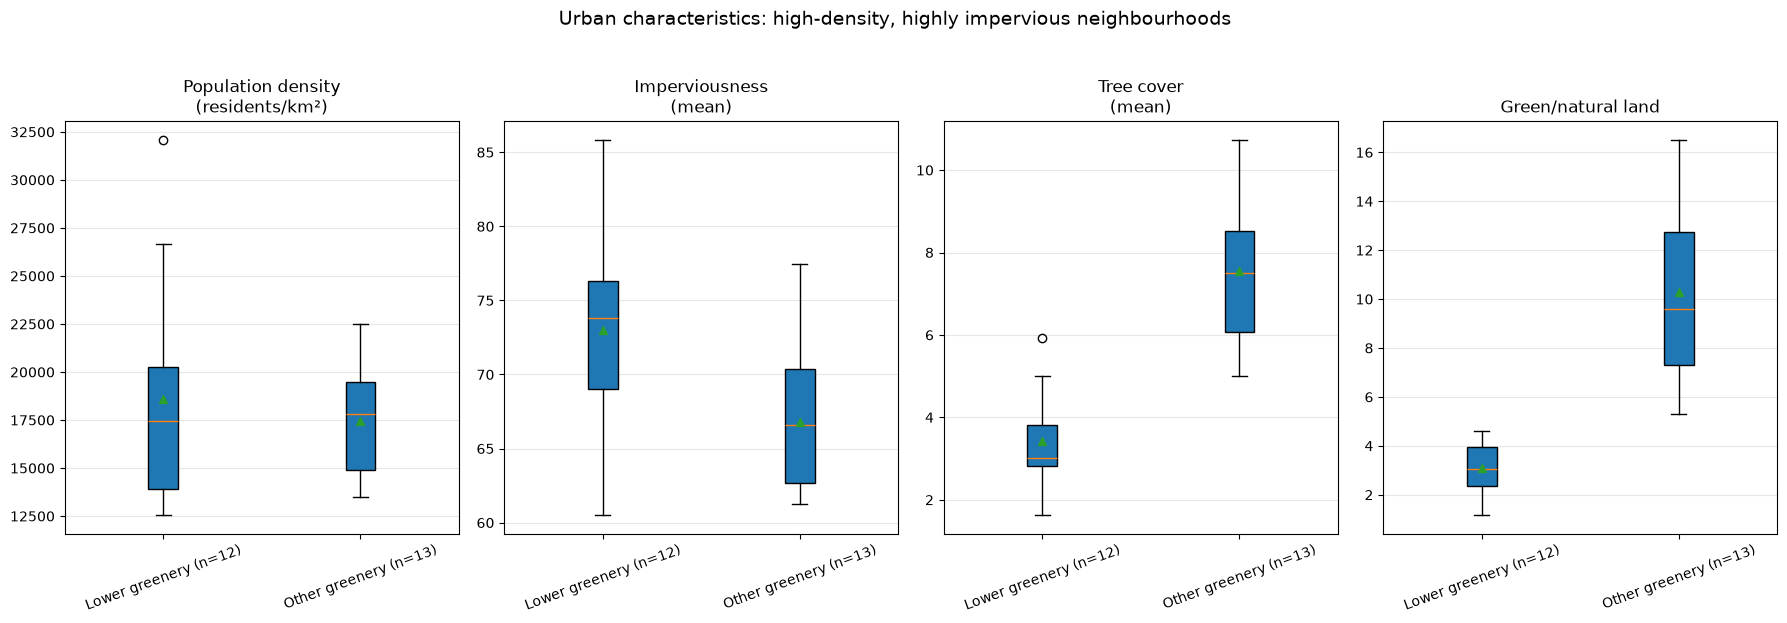

In [24]:
import matplotlib.pyplot as plt

# Define the indicators and their display labels
plot_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

plot_labels = [
    "Population density\n(residents/km²)",
    "Imperviousness\n(mean)",
    "Tree cover\n(mean)",
    "Green/natural land"
]

# Prepare the two groups
groups = [lower_greenery, other_greenery]
group_labels = ["Lower greenery (n=12)", "Other greenery (n=13)"]

# Create four separate boxplots
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for ax, col, label in zip(axes, plot_cols, plot_labels):

    # Collect values for each group
    data = [group[col].dropna() for group in groups]

    # Draw the boxplots
    ax.boxplot(
        data,
        tick_labels=group_labels,
        patch_artist=True,
        showmeans=True
    )

    ax.set_title(label)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Urban characteristics: high-density, highly impervious neighbourhoods",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

Within the 25 neighbourhoods in the upper quartiles of population density and imperviousness, we identified 12 neighbourhoods that also fell into the lower quartiles for both tree cover and green/natural land. These were classified as the "Lower greenery" group. The remaining 13 neighbourhoods formed the "Other greenery" comparison group.

Despite similar population densities, the Lower greenery group showed higher median imperviousness and substantially lower median values for both greenery indicators.

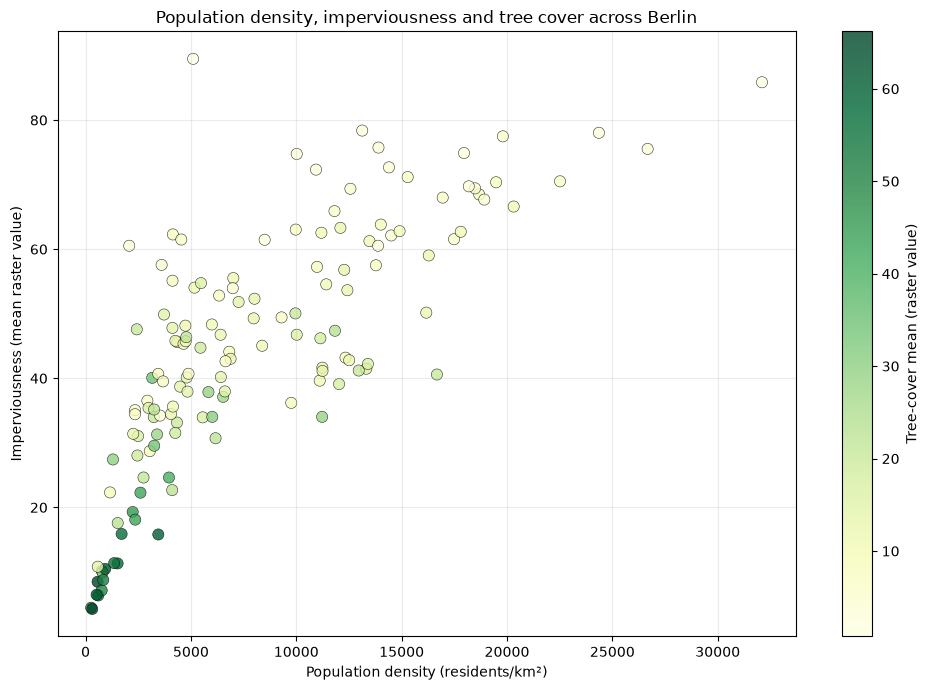

In [25]:
# Keep neighbourhoods with complete population density data
plot_df = urban_df.dropna(
    subset=["population_density_km2", "imperviousness_mean", "tree_cover_mean"]
)

# Create scatter plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    plot_df["population_density_km2"],
    plot_df["imperviousness_mean"],
    c=plot_df["tree_cover_mean"],
    cmap="YlGn",
    s=65,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4
)

# Add labels and title
plt.xlabel("Population density (residents/km²)")
plt.ylabel("Imperviousness (mean raster value)")
plt.title("Population density, imperviousness and tree cover across Berlin")

# Add colour scale for tree cover
cbar = plt.colorbar(scatter)
cbar.set_label("Tree-cover mean (raster value)")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Positive density–imperviousness relationship: This is consistent with the Spearman correlation of 0.802. More densely populated neighbourhoods generally tend to have higher imperviousness values.

Lower tree cover in denser areas: The colour pattern suggests that neighbourhoods with higher population density and imperviousness tend to have lower tree-cover values. This is consistent with the negative Spearman correlations:
- Density vs. tree cover: −0.580
- Imperviousness vs. tree cover: −0.788

High-density plateau: The plot appears to show that imperviousness remains relatively high across many densely populated neighbourhoods, rather than increasing indefinitely.

Two interesting outliers: The neighbourhood above 32,000 residents/km² and the one with approximately 90% imperviousness deserve further investigation.

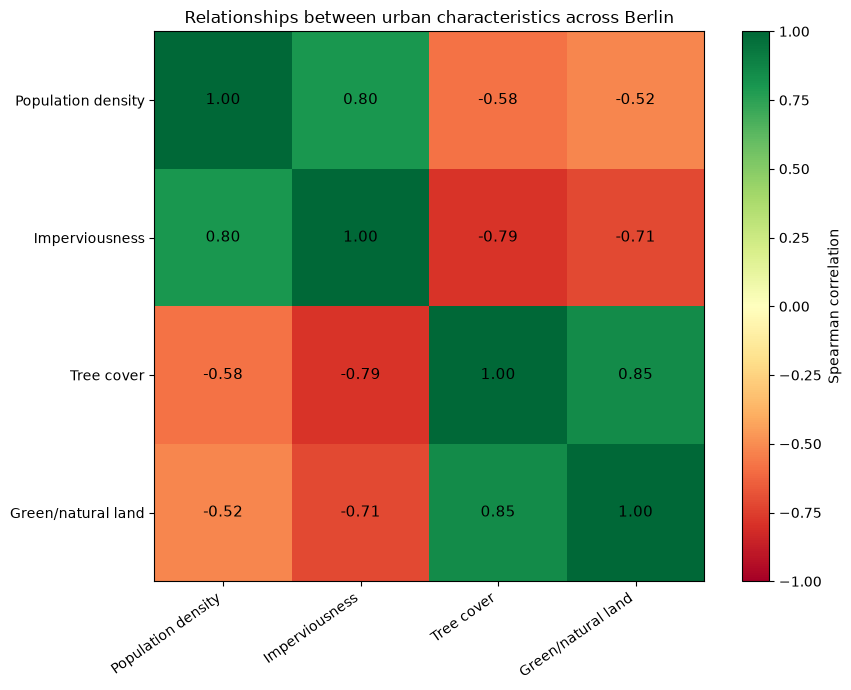

In [26]:
# Select indicators and calculate Spearman correlations
corr_cols = [
    "population_density_km2",
    "imperviousness_mean",
    "tree_cover_mean",
    "green_natural"
]

corr_matrix = urban_df[corr_cols].corr(method="spearman")

# Create readable axis labels
labels = [
    "Population density",
    "Imperviousness",
    "Tree cover",
    "Green/natural land"
]

# Draw the heatmap
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    corr_matrix,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

# Add correlation values inside each cell
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr_matrix.iloc[i, j]
        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=11
        )

# Set axis labels
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)

# Add colour scale
cbar = plt.colorbar(image, ax=ax)
cbar.set_label("Spearman correlation")

ax.set_title("Relationships between urban characteristics across Berlin")
plt.tight_layout()
plt.show()

The correlation analysis reveals a clear relationship between Berlin's built environment and its vegetation patterns. Population density is strongly positively associated with imperviousness (Spearman ρ = 0.80), while imperviousness is strongly negatively associated with tree cover (ρ = −0.79). Tree cover and green/natural land also show a strong positive association (ρ = 0.85).

These patterns suggest that densely populated, highly sealed neighbourhoods tend to have less tree cover and less green/natural land. However, the correlations describe spatial associations and do not establish causal relationships.

In [28]:
# Select the 10 neighbourhoods with the highest population density
top_10_density = (
    urban_df
    .dropna(subset=["population_density_km2"])
    .nlargest(10, "population_density_km2")
    .sort_values("population_density_km2", ascending=True)
)

# Display the selected neighbourhoods and their indicators
top_10_density[
    [
        "bzr_name",
        "bez",
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].round(2)

,bzr_name,bez,population_density_km2,imperviousness_mean,tree_cover_mean
64,Schöneberg Südwest,07 - Tempelhof-Schöneberg,18483.98,69.42,5.09
3,Brunnenstraße Süd,01 - Mitte,18679.65,68.48,7.93
80,Rixdorf,08 - Neukölln,18920.39,67.69,4.48
78,Neuköllner Mitte/Zentrum,08 - Neukölln,19482.19,70.36,7.51
32,Prenzlauer Berg Südwest,03 - Pankow,19804.45,77.48,5.12
33,Prenzlauer Berg Süd,03 - Pankow,20316.37,66.60,10.19
9,Wedding Zentrum,01 - Mitte,22515.30,70.51,6.45
16,Frankfurter Allee Nord,02 - Friedrichshain-Kreuzberg,24361.54,78.03,2.85
79,Reuterstraße,08 - Neukölln,26674.50,75.53,3.28
30,Helmholtzplatz,03 - Pankow,32100.38,85.86,1.64


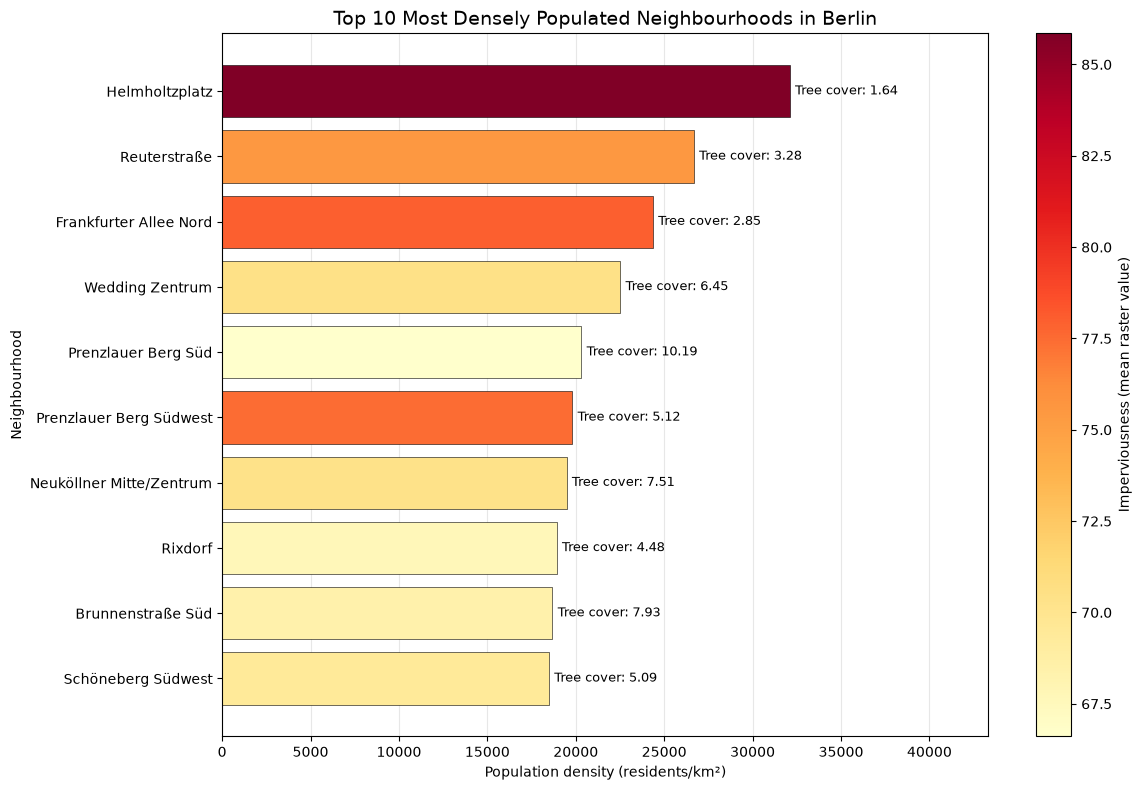

In [29]:
import matplotlib.colors as mcolors

# Set up the figure
fig, ax = plt.subplots(figsize=(12, 8))

# Colour bars according to imperviousness
norm = mcolors.Normalize(
    vmin=top_10_density["imperviousness_mean"].min(),
    vmax=top_10_density["imperviousness_mean"].max()
)

colors = plt.cm.YlOrRd(
    norm(top_10_density["imperviousness_mean"])
)

# Draw horizontal bars
bars = ax.barh(
    top_10_density["bzr_name"],
    top_10_density["population_density_km2"],
    color=colors,
    edgecolor="black",
    linewidth=0.4
)

# Add tree-cover values at the end of each bar
for bar, tree_value in zip(
    bars,
    top_10_density["tree_cover_mean"]
):
    ax.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height() / 2,
        f"Tree cover: {tree_value:.2f}",
        va="center",
        fontsize=9
    )

# Add colour scale for imperviousness
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Imperviousness (mean raster value)")

# Add titles and labels
ax.set_title(
    "Top 10 Most Densely Populated Neighbourhoods in Berlin",
    fontsize=14
)
ax.set_xlabel("Population density (residents/km²)")
ax.set_ylabel("Neighbourhood")

# Leave room for the tree-cover labels
ax.set_xlim(
    0,
    top_10_density["population_density_km2"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Helmholtzplatz represents the most extreme case among Berlin's ten most densely populated neighbourhoods, combining approximately 32,100 residents/km² with the highest imperviousness mean (85.86) and lowest tree-cover mean (1.64) in this group.

However, the comparison also reveals variation among similarly dense neighbourhoods. Prenzlauer Berg Süd, for example, retains a considerably higher tree-cover mean (10.19), despite a population density exceeding 20,000 residents/km². This illustrates that densely populated neighbourhoods do not all share the same urban vegetation profile.

In [31]:
import geopandas as gpd

# Load the Berlin neighbourhood boundaries
lor_gdf = gpd.read_file("satellite_data/berlin_lor_2021.geojson")

# Inspect the dataset
print("Rows:", len(lor_gdf))
print("CRS:", lor_gdf.crs)
print("\nColumns:")
print(lor_gdf.columns.tolist())

print("\nFirst 5 rows:")
display(lor_gdf.head())

Rows: 143
CRS: EPSG:4326

Columns:
['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand', 'geometry']

First 5 rows:


,id,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand,geometry
0,b_lor_bzr_2021.011001,011001,Tiergarten Süd,0110,Zentrum,01 - Mitte,5.172481e+06,01.12.2021,"MULTIPOLYGON (((13.33601 52.51379, 13.33587 52..."
1,b_lor_bzr_2021.011002,011002,Regierungsviertel,0110,Zentrum,01 - Mitte,2.695511e+06,01.01.2021,"MULTIPOLYGON (((13.3765 52.51602, 13.37651 52...."
2,b_lor_bzr_2021.011003,011003,Alexanderplatz,0110,Zentrum,01 - Mitte,6.228825e+06,01.01.2021,"MULTIPOLYGON (((13.37357 52.52788, 13.37364 52..."
3,b_lor_bzr_2021.011004,011004,Brunnenstraße Süd,0110,Zentrum,01 - Mitte,1.755196e+06,01.01.2021,"MULTIPOLYGON (((13.39586 52.53809, 13.39569 52..."
4,b_lor_bzr_2021.012005,012005,Moabit West,0120,Moabit,01 - Mitte,4.305047e+06,01.01.2021,"MULTIPOLYGON (((13.33422 52.51677, 13.33431 52..."


In [32]:
# Standardise neighbourhood IDs as six-character strings
lor_gdf["bzr_id"] = lor_gdf["bzr_id"].astype(str).str.zfill(6)
urban_df["bzr_id"] = urban_df["bzr_id"].astype(str).str.zfill(6)

# Check for duplicate IDs before joining
print("Duplicate boundary IDs:", lor_gdf["bzr_id"].duplicated().sum())
print("Duplicate urban data IDs:", urban_df["bzr_id"].duplicated().sum())

# Join the indicators to the geographic boundaries
urban_map_gdf = lor_gdf.merge(
    urban_df,
    on="bzr_id",
    how="left",
    validate="one_to_one",
    indicator=True,
    suffixes=("_boundary", "_data")
)

# Check the join results
print("\nJoin results:")
print(urban_map_gdf["_merge"].value_counts())

print("\nUnmatched boundaries:")
display(
    urban_map_gdf.loc[
        urban_map_gdf["_merge"] != "both",
        ["bzr_id", "bzr_name_boundary"]
    ]
)

Duplicate boundary IDs: 0
Duplicate urban data IDs: 0

Join results:
_merge
both          143
left_only       0
right_only      0
Name: count, dtype: int64

Unmatched boundaries:


,bzr_id,bzr_name_boundary


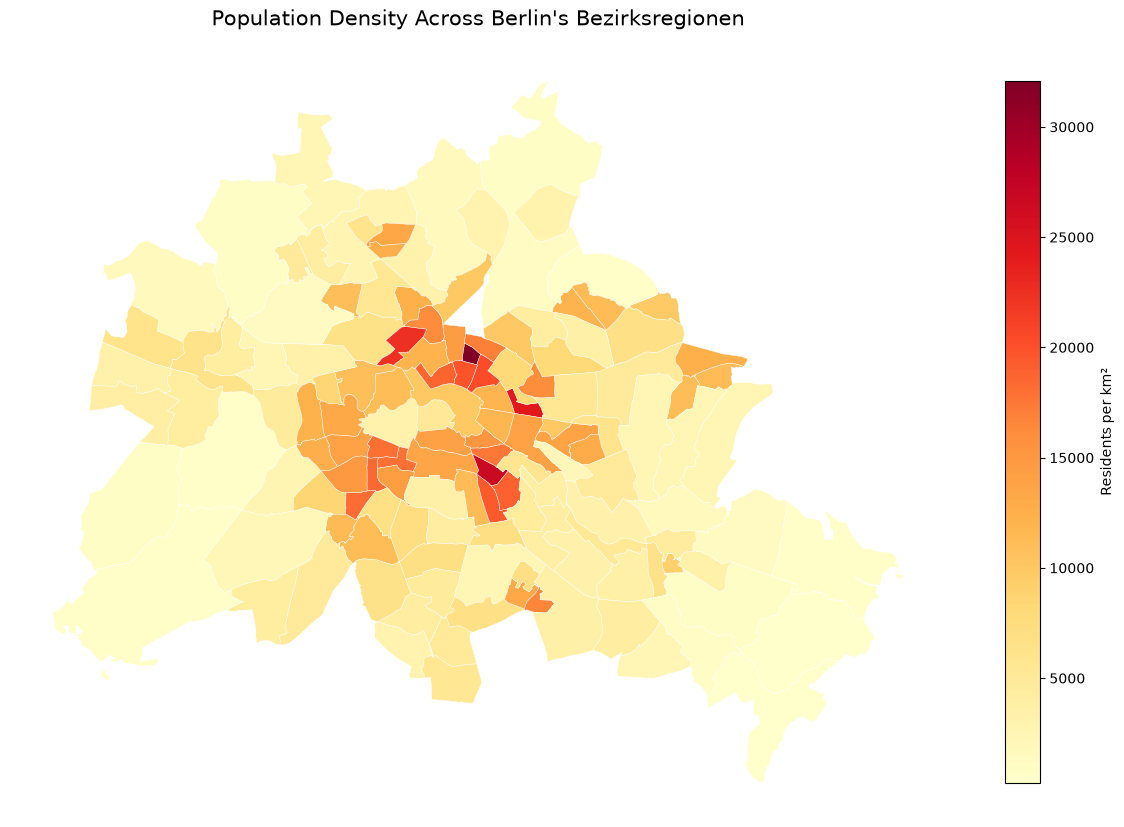

In [33]:
# Exclude neighbourhoods with missing population density
density_map = urban_map_gdf.dropna(
    subset=["population_density_km2"]
)

fig, ax = plt.subplots(figsize=(12, 12))

# Create the choropleth map
density_map.plot(
    column="population_density_km2",
    cmap="YlOrRd",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Residents per km²",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "Population Density Across Berlin's Bezirksregionen",
    fontsize=15,
    pad=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

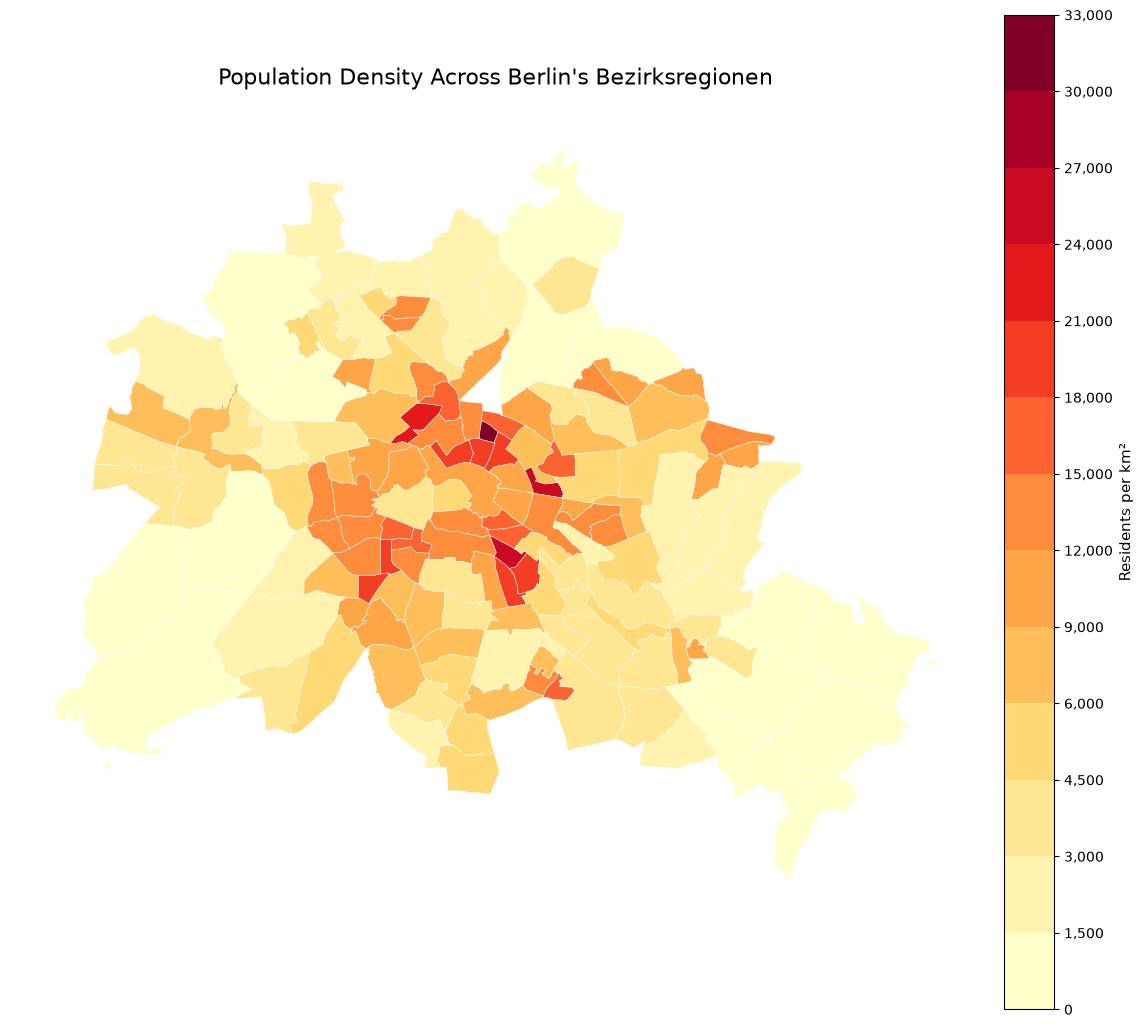

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import numpy as np

# Exclude missing population density values
density_map = urban_map_gdf.dropna(
    subset=["population_density_km2"]
)

# Use smaller intervals at the lower end
bounds = [0, 1500, 3000, 4500, 6000, 9000,
          12000, 15000, 18000, 21000, 24000,
          27000, 30000, 33000]

# Create a discrete colour scale
cmap = plt.get_cmap("YlOrRd", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot population density
density_map.plot(
    column="population_density_km2",
    cmap=cmap,
    norm=norm,
    linewidth=0.35,
    edgecolor="white",
    ax=ax
)

# Add the colour legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=bounds,
    ticks=bounds,
    shrink=0.85,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

cbar.set_label("Residents per km²", fontsize=11)

ax.set_title(
    "Population Density Across Berlin's Bezirksregionen",
    fontsize=16,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

1. Central concentration of high population density

The highest population densities, ranging from approximately 18,000 to over 30,000 residents/km², are concentrated in Berlin's inner-city neighbourhoods. Helmholtzplatz stands out as the most densely populated area, followed by other densely populated neighbourhoods in districts such as Friedrichshain-Kreuzberg, Neukölln and Mitte. This confirms the strong concentration of residents in central Berlin.

2. Lower population density in peripheral areas

The outer parts of Berlin are predominantly characterised by lower population densities, with many neighbourhoods falling below 3,000 residents/km². This contrasts sharply with the densely populated inner city and reflects Berlin's uneven spatial distribution of residents. Large green spaces, forests and water bodies may contribute to this pattern, although the population-density map alone does not establish their individual influence.

3. Intermediate-density areas beyond the city centre

Neighbourhoods with moderate population densities (approximately 9,000–15,000 residents/km²) form pockets between the densely populated centre and the lower-density periphery. These variations show that population density does not decline uniformly from the city centre towards the outskirts.

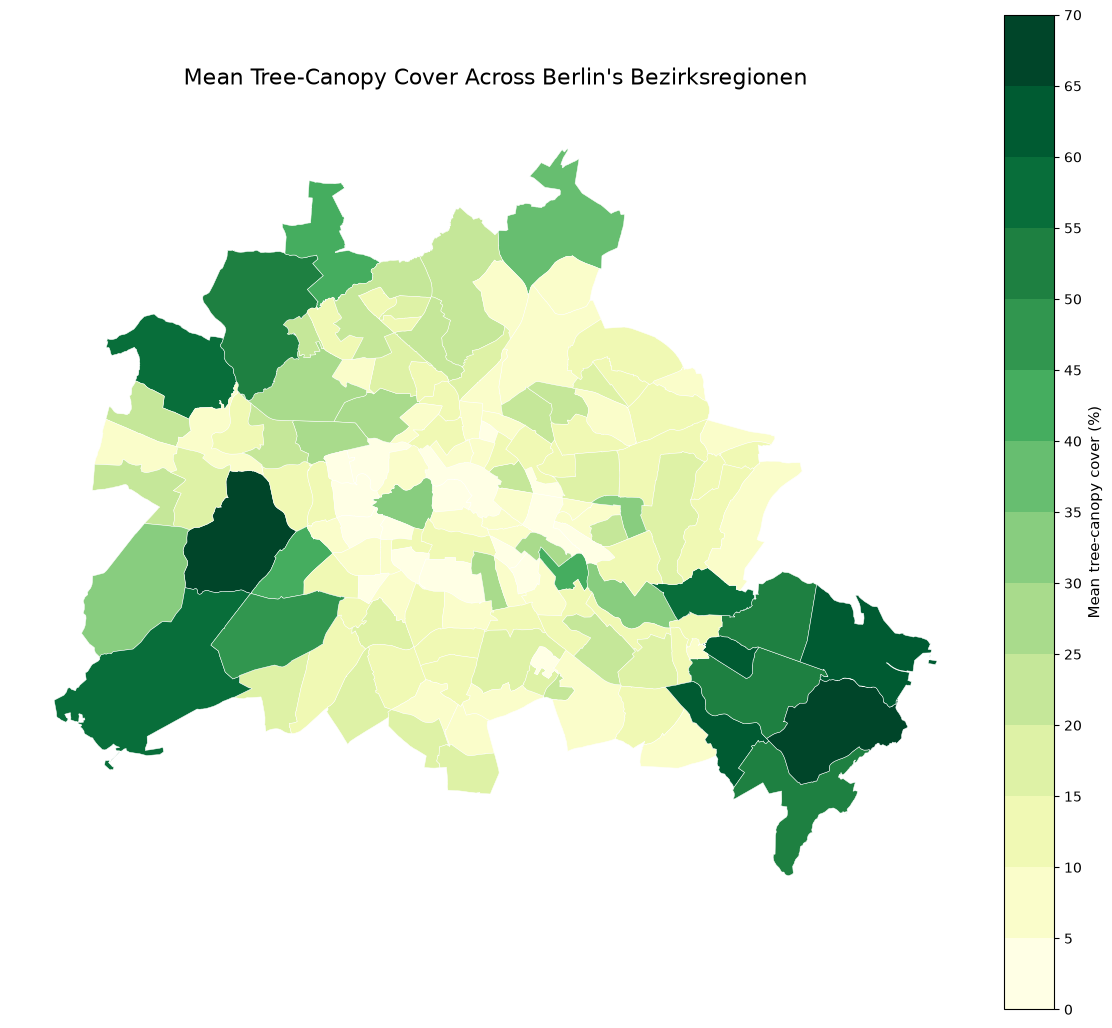

In [42]:
# Exclude missing tree-cover values
tree_map = urban_map_gdf.dropna(
    subset=["tree_cover_mean"]
)

# Define intervals every 5 percentage points
bounds = np.arange(0, 71, 5)

# Create a discrete green colour scale with more shades
cmap = plt.get_cmap("YlGn", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(12, 12))

# Plot mean tree-canopy cover
tree_map.plot(
    column="tree_cover_mean",
    cmap=cmap,
    norm=norm,
    linewidth=0.35,
    edgecolor="white",
    ax=ax
)

# Add the colour legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=bounds,
    ticks=bounds,
    shrink=0.85,
    pad=0.02
)

cbar.ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:.0f}")
)

cbar.set_label("Mean tree-canopy cover (%)", fontsize=11)

# Add title and improve layout
ax.set_title(
    "Mean Tree-Canopy Cover Across Berlin's Bezirksregionen",
    fontsize=16,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

Key points:
- Greener outskirts: The highest mean canopy-cover values are concentrated in southeastern and western/southwestern Berlin, particularly around forested areas such as Köpenick, Grunewald and Wannsee.
- Less canopy in the urban core: Central neighbourhoods, including Mitte, Friedrichshain-Kreuzberg and parts of Neukölln, generally show lower mean tree-canopy cover.
- Intermediate transition zones: Parts of northern Berlin, including Pankow and Reinickendorf, display moderate levels of canopy cover.
- Uneven spatial distribution: Tree canopy varies considerably between neighbourhoods, highlighting differences in their urban environmental characteristics.

In [ ]:
#creating combined urban-exposure map

# Keep neighbourhoods with complete data
exposure_df = urban_df.dropna(
    subset=[
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
).copy()

# Check the number of neighbourhoods
print("Number of neighbourhoods:", len(exposure_df))

Number of neighbourhoods: 141


In [ ]:
# Calculate quartile thresholds

#Population density: upper quartile = relatively high.
#Imperviousness: upper quartile = relatively high.
#Tree-canopy cover: lower quartile = relatively low.


density_q3 = exposure_df["population_density_km2"].quantile(0.75)
impervious_q3 = exposure_df["imperviousness_mean"].quantile(0.75)
tree_cover_q1 = exposure_df["tree_cover_mean"].quantile(0.25)

# Identify neighbourhoods meeting all three criteria
exposure_df["high_density"] = (
    exposure_df["population_density_km2"] >= density_q3
)

exposure_df["high_imperviousness"] = (
    exposure_df["imperviousness_mean"] >= impervious_q3
)

exposure_df["low_tree_cover"] = (
    exposure_df["tree_cover_mean"] <= tree_cover_q1
)

# Combine the three conditions
exposure_df["high_urban_exposure"] = (
    exposure_df["high_density"] &
    exposure_df["high_imperviousness"] &
    exposure_df["low_tree_cover"]
)

# Check the thresholds and number of matching neighbourhoods
print("Population density Q3:", density_q3)
print("Imperviousness Q3:", impervious_q3)
print("Tree-cover Q1:", tree_cover_q1)

print(
    "Neighbourhoods meeting all three criteria:",
    exposure_df["high_urban_exposure"].sum()
)

Population density Q3: 12273.260042645876
Imperviousness Q3: 60.527451470465714
Tree-cover Q1: 7.158448309733577
Neighbourhoods meeting all three criteria: 18


In [45]:
# Select neighbourhoods meeting all three criteria
high_exposure_areas = (
    exposure_df[exposure_df["high_urban_exposure"]]
    .sort_values(
        "population_density_km2",
        ascending=False
    )
)

# Display the neighbourhoods and their indicators
high_exposure_areas[
    [
        "bzr_name",
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].round(2)

,bzr_name,population_density_km2,imperviousness_mean,tree_cover_mean
30,Helmholtzplatz,32100.38,85.86,1.64
79,Reuterstraße,26674.50,75.53,3.28
16,Frankfurter Allee Nord,24361.54,78.03,2.85
9,Wedding Zentrum,22515.30,70.51,6.45
32,Prenzlauer Berg Südwest,19804.45,77.48,5.12
80,Rixdorf,18920.39,67.69,4.48
64,Schöneberg Südwest,18483.98,69.42,5.09
66,Friedenau West,18187.19,69.74,2.83
62,Schöneberg Nordwest,17959.02,74.90,2.80
13,Südliche Luisenstadt,17486.11,61.54,6.60


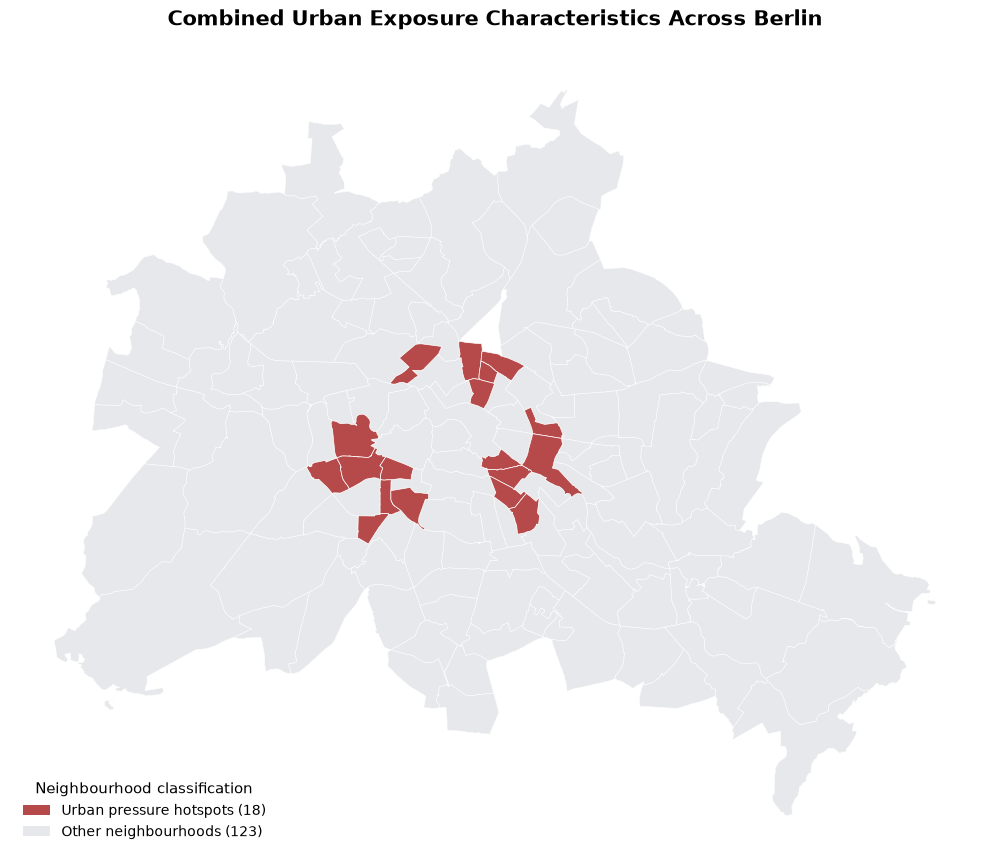

In [60]:
# Separate neighbourhoods by classification
selected = exposure_map_gdf[
    exposure_map_gdf["high_urban_exposure"] == True
]

not_selected = exposure_map_gdf[
    exposure_map_gdf["high_urban_exposure"] == False
]

# Create the map
fig, ax = plt.subplots(figsize=(10, 10))

# Plot neighbourhoods that do not meet all three criteria
not_selected.plot(
    color="#E6E8EB",
    edgecolor="white",
    linewidth=0.35,
    ax=ax
)

# Plot neighbourhoods that meet all three criteria
selected.plot(
    color="#B64A4A",
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# legend
legend_items = [
    Patch(
        facecolor="#B64A4A",
        label=f"Urban pressure hotspots ({len(selected)})"
    ),
    Patch(
        facecolor="#E6E8EB",
        label=f"Other neighbourhoods ({len(not_selected)})"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    frameon=False,
    fontsize=10,
    title="Neighbourhood classification",
    title_fontsize=11
)
# Add title
ax.set_title(
    "Combined Urban Exposure Characteristics Across Berlin",
    fontsize=15,
    fontweight="bold",
    pad=20
)

# Remove axes
ax.set_axis_off()

plt.tight_layout()
plt.show()


- 18 of 141 neighbourhoods (12.8%) combine high population density, high imperviousness and low tree-canopy cover.
- These neighbourhoods are predominantly concentrated in inner Berlin, particularly around and within the S-Bahn Ring.
- The pattern is not uniform: some central neighbourhoods do not meet all three criteria, highlighting differences in urban structure across the city.
- These areas could be prioritised for further investigation into urban heat exposure and potential green-infrastructure interventions.

Merging weather/air quality/water quality stations into LOR

In [ ]:
#loading the weather complete dataset

import pandas as pd

weather_all_df = pd.read_csv("merged_complete_datasets/df_weather_combined_all_updated.csv")

In [23]:
# Check all weather stations and their data coverage
weather_all_df.groupby(["source", "station"]).agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    records=("date", "count")
).reset_index()

,source,station,first_date,last_date,records
0,DWD,Berlin Brandenburg,2025-04-09 00:00:00,2026-10-10 00:00:00,550
1,DWD,Buch,2025-04-09 00:00:00,2026-10-10 00:00:00,550
2,DWD,Dahlem,2025-04-09 00:00:00,2026-10-10 00:00:00,550
3,DWD,Marzahn,2025-04-09 00:00:00,2026-10-10 00:00:00,550
4,DWD,Tempelhof,2025-04-09 00:00:00,2026-10-10 00:00:00,550
5,Meteostat,Alexanderplatz,2025-01-01 00:00:00,2026-10-30 00:00:00,668
6,Meteostat,Dahlem,2026-01-01 00:00:00,2026-10-30 00:00:00,303
7,Meteostat,Marzahn,2026-01-01 00:00:00,2026-10-30 00:00:00,303
8,Meteostat,Tegel,2025-01-01 00:00:00,2026-10-30 00:00:00,668
9,Meteostat,Tempelhof,2026-01-01 00:00:00,2026-10-30 00:00:00,303


In [24]:
# Weather station coordinates
weather_stations = pd.DataFrame([
    ["Berlin Brandenburg", "DWD", 52.3807, 13.5306],
    ["Buch", "DWD", 52.6309, 13.5022],
    ["Dahlem", "DWD", 52.4537, 13.3017],
    ["Marzahn", "DWD", 52.5447, 13.5598],
    ["Tempelhof", "DWD", 52.4676, 13.4020],
    ["Alexanderplatz", "Meteostat", 52.5167, 13.4167],
    ["Dahlem", "Meteostat", 52.4667, 13.3000],
    ["Marzahn", "Meteostat", 52.5447, 13.5598],
    ["Tegel", "Meteostat", 52.5667, 13.3167],
    ["Tempelhof", "Meteostat", 52.4667, 13.4000]
], columns=["station", "source", "latitude", "longitude"])

# Add a station type for later map styling
weather_stations["station_type"] = "Weather"

# Display the coordinate table
weather_stations

,station,source,latitude,longitude,station_type
0,Berlin Brandenburg,DWD,52.3807,13.5306,Weather
1,Buch,DWD,52.6309,13.5022,Weather
2,Dahlem,DWD,52.4537,13.3017,Weather
3,Marzahn,DWD,52.5447,13.5598,Weather
4,Tempelhof,DWD,52.4676,13.4020,Weather
5,Alexanderplatz,Meteostat,52.5167,13.4167,Weather
6,Dahlem,Meteostat,52.4667,13.3000,Weather
7,Marzahn,Meteostat,52.5447,13.5598,Weather
8,Tegel,Meteostat,52.5667,13.3167,Weather
9,Tempelhof,Meteostat,52.4667,13.4000,Weather


In [25]:
# Get unique station/source combinations from the weather dataset
weather_inventory = weather_all_df[
    ["station", "source"]
].drop_duplicates()

# Compare the inventory with the coordinate table
station_check = weather_inventory.merge(
    weather_stations[["station", "source"]],
    on=["station", "source"],
    how="left",
    indicator=True
)

print(station_check)
print("\nUnmatched stations:")
print(station_check[station_check["_merge"] == "left_only"])

              station     source _merge
0  Berlin Brandenburg        DWD   both
1                Buch        DWD   both
2              Dahlem        DWD   both
3             Marzahn        DWD   both
4           Tempelhof        DWD   both
5      Alexanderplatz  Meteostat   both
6              Dahlem  Meteostat   both
7             Marzahn  Meteostat   both
8               Tegel  Meteostat   both
9           Tempelhof  Meteostat   both

Unmatched stations:
Empty DataFrame
Columns: [station, source, _merge]
Index: []


In [ ]:
#loading the air quality complete dataset

df_air_quality = pd.read_csv("merged_complete_datasets/berlin_air_quality_master_2025_2026.csv")

df_air_quality.head()

,datetime,station,core,component,period,value,station_name,station_type
0,2024-12-31 23:00:00+00:00,mc010,ebc,ebc_24h,24h,0.5,Wedding,Urban background
1,2024-12-31 23:00:00+00:00,mc010,no2,no2_24h,24h,9.0,Wedding,Urban background
2,2024-12-31 23:00:00+00:00,mc010,no,no_24h,24h,2.0,Wedding,Urban background
3,2024-12-31 23:00:00+00:00,mc010,nox,nox_24h,24h,12.0,Wedding,Urban background
4,2024-12-31 23:00:00+00:00,mc010,o3,o3_24h,24h,49.0,Wedding,Urban background


In [ ]:
# List each unique air-quality station
air_station_inventory = (
    df_air_quality[
        ["station", "station_name", "station_type"]
    ]
    .drop_duplicates()
    .sort_values("station")
)

print(air_station_inventory.to_string(index=False))

station      station_name     station_type
  mc010           Wedding Urban background
  mc027       Marienfelde        Outskirts
  mc032         Grunewald        Outskirts
  mc042          Neukölln Urban background
  mc077              Buch        Outskirts
  mc085   Friedrichshagen        Outskirts
  mc117  Schildhornstraße          Traffic
  mc124 Mariendorfer Damm          Traffic
  mc144 Silbersteinstraße          Traffic
  mc145           Frohnau        Outskirts
  mc171             Mitte Urban background
  mc174 Frankfurter Allee          Traffic
  mc190  Leipziger Straße          Traffic
  mc221  Karl-Marx-Straße          Traffic
  mc282        Karlshorst Urban background


In [30]:
# Create the air-quality station coordinate table
air_stations = pd.DataFrame([
    ["mc010", "Wedding", "Urban background", 52.542855, 13.349353],
    ["mc027", "Marienfelde", "Outskirts", 52.397909, 13.367526],
    ["mc032", "Grunewald", "Outskirts", 52.473080, 13.224957],
    ["mc042", "Neukölln", "Urban background", 52.489442, 13.430847],
    ["mc077", "Buch", "Outskirts", 52.642739, 13.481295],
    ["mc085", "Friedrichshagen", "Outskirts", 52.449899, 13.646985],
    ["mc117", "Schildhornstraße", "Traffic", 52.463600, 13.318226],
    ["mc124", "Mariendorfer Damm", "Traffic", 52.438125, 13.387755],
    ["mc144", "Silbersteinstraße", "Traffic", 52.467461, 13.441213],
    ["mc145", "Frohnau", "Outskirts", 52.653270, 13.296080],
    ["mc171", "Mitte", "Urban background", 52.513611, 13.418801],
    ["mc174", "Frankfurter Allee", "Traffic", 52.514034, 13.470115],
    ["mc190", "Leipziger Straße", "Traffic", 52.509810, 13.382377],
    ["mc221", "Karl-Marx-Straße", "Traffic", 52.483807, 13.429663],
    ["mc282", "Karlshorst", "Urban background", 52.485307, 13.529596]
], columns=[
    "station", "station_name", "station_type",
    "latitude", "longitude"
])

print(air_stations.shape)
print(air_stations.head())

(15, 5)
  station station_name      station_type   latitude  longitude
0   mc010      Wedding  Urban background  52.542855  13.349353
1   mc027  Marienfelde         Outskirts  52.397909  13.367526
2   mc032    Grunewald         Outskirts  52.473080  13.224957
3   mc042     Neukölln  Urban background  52.489442  13.430847
4   mc077         Buch         Outskirts  52.642739  13.481295


In [31]:
# Compare air-quality station inventory with coordinate table
air_station_inventory = df_air_quality[
    ["station", "station_name", "station_type"]
].drop_duplicates()

air_station_check = air_station_inventory.merge(
    air_stations,
    on=["station", "station_name", "station_type"],
    how="left",
    indicator=True
)

print("Total stations:", len(air_station_check))
print("Matched stations:", (air_station_check["_merge"] == "both").sum())
print("Missing coordinates:", air_station_check["latitude"].isna().sum())

print("\nUnmatched stations:")
print(air_station_check[air_station_check["_merge"] != "both"])

Total stations: 15
Matched stations: 15
Missing coordinates: 0

Unmatched stations:
Empty DataFrame
Columns: [station, station_name, station_type, latitude, longitude, _merge]
Index: []


In [32]:
#loading the water quality complete dataset

df_water_quality = pd.read_csv("merged_complete_datasets/berlin_water_quality_cleaned.csv")

df_water_quality.head()

,date,bathing_water_quality,coliform_bacteria,cyanobacteria_chl_a,e_coli,intestinal_enterococci,water_visibility_depth,water_temperature,lake,water_temperature_raw,...,e_coli_numeric,intestinal_enterococci_raw,intestinal_enterococci_qualifier,intestinal_enterococci_numeric,cyanobacteria_chl_a_raw,cyanobacteria_chl_a_qualifier,cyanobacteria_chl_a_numeric,water_visibility_depth_raw,water_visibility_depth_qualifier,water_visibility_depth_numeric
0,2025-04-29,Suitable for bathing,< 300,"0,0000","< 15,00","< 15,00","> 1,00","16,00",Flughafensee,"16,00",...,15.0,"< 15,00",<,15.0,"0,0000",NaN,0.0,"> 1,00",>,1.0
1,2025-05-15,Suitable for bathing,< 300,"0,20","< 15,00","< 15,00","> 1,00","17,50",Flughafensee,"17,50",...,15.0,"< 15,00",<,15.0,"0,20",NaN,0.2,"> 1,00",>,1.0
2,2025-05-26,Suitable for bathing,360,"0,10","30,00","15,00",NaN,"17,70",Flughafensee,"17,70",...,30.0,"15,00",NaN,15.0,"0,10",NaN,0.1,NaN,NaN,NaN
3,2025-06-11,NaN,null 910,"null 0,30","null 30,00","null 15,00","> 1,00","null 17,80",Flughafensee,"null 17,80",...,30.0,"null 15,00",NaN,15.0,"null 0,30",NaN,0.3,"> 1,00",>,1.0
4,2025-07-10,NaN,< 300,"null 0,0000","null 15,00","null 15,00","> 1,00","null 21,50",Flughafensee,"null 21,50",...,15.0,"null 15,00",NaN,15.0,"null 0,0000",NaN,0.0,"> 1,00",>,1.0


In [33]:
# Create the bathing-water station coordinate table
water_stations = pd.DataFrame([
    ["B920", "Flughafensee", 52.5698, 13.2849],
    ["B350", "Wannsee", 52.4389, 13.1768],
    ["B116", "Müggelsee", 52.4447, 13.6759],
    ["B911", "Orankesee", 52.5496, 13.4843],
    ["B309", "Tegeler See", 52.5778, 13.2453],
    ["B910", "Weißensee", 52.5540, 13.4656]
], columns=[
    "station", "lake", "latitude", "longitude"
])

water_stations["station_type"] = "Bathing water"

print(water_stations.to_string(index=False))

station         lake  latitude  longitude  station_type
   B920 Flughafensee   52.5698    13.2849 Bathing water
   B350      Wannsee   52.4389    13.1768 Bathing water
   B116    Müggelsee   52.4447    13.6759 Bathing water
   B911    Orankesee   52.5496    13.4843 Bathing water
   B309  Tegeler See   52.5778    13.2453 Bathing water
   B910    Weißensee   52.5540    13.4656 Bathing water


In [34]:
# Check unique lakes in the water-quality dataset
print(sorted(df_water_quality["lake"].dropna().unique()))

['Flughafensee', 'Müggelsee', 'Orankesee', 'Tegeler See', 'Wannsee', 'Weißensee']


In [35]:
# Get unique lakes from the water-quality dataset
water_inventory = (
    df_water_quality[["lake"]]
    .drop_duplicates()
    .sort_values("lake")
)

# Compare the inventory with the coordinate table
water_station_check = water_inventory.merge(
    water_stations[["lake", "station", "latitude", "longitude"]],
    on="lake",
    how="left",
    indicator=True
)

print("Total lakes:", len(water_station_check))
print("Matched lakes:", (water_station_check["_merge"] == "both").sum())
print("Missing coordinates:", water_station_check["latitude"].isna().sum())

print("\nUnmatched lakes:")
print(water_station_check[water_station_check["_merge"] != "both"])

Total lakes: 6
Matched lakes: 6
Missing coordinates: 0

Unmatched lakes:
Empty DataFrame
Columns: [lake, station, latitude, longitude, _merge]
Index: []


In [36]:
# Standardise weather station columns
weather_stations_clean = weather_stations[
    ["station", "source", "station_type", "latitude", "longitude"]
].copy()

# Standardise air-quality station columns
air_stations_clean = air_stations[
    ["station", "station_type", "latitude", "longitude"]
].copy()

air_stations_clean["source"] = "Berlin Air Quality"

# Standardise bathing-water station columns
water_stations_clean = water_stations[
    ["station", "station_type", "latitude", "longitude"]
].copy()

water_stations_clean["source"] = "Berlin Water Quality"

# Combine all station tables
all_stations = pd.concat(
    [
        weather_stations_clean,
        air_stations_clean,
        water_stations_clean
    ],
    ignore_index=True
)

# Display the combined dataset
print("Shape:", all_stations.shape)
print(all_stations.head(10))

Shape: (31, 5)
              station     source station_type  latitude  longitude
0  Berlin Brandenburg        DWD      Weather   52.3807    13.5306
1                Buch        DWD      Weather   52.6309    13.5022
2              Dahlem        DWD      Weather   52.4537    13.3017
3             Marzahn        DWD      Weather   52.5447    13.5598
4           Tempelhof        DWD      Weather   52.4676    13.4020
5      Alexanderplatz  Meteostat      Weather   52.5167    13.4167
6              Dahlem  Meteostat      Weather   52.4667    13.3000
7             Marzahn  Meteostat      Weather   52.5447    13.5598
8               Tegel  Meteostat      Weather   52.5667    13.3167
9           Tempelhof  Meteostat      Weather   52.4667    13.4000


In [37]:
# Check missing values
print("Missing values:")
print(all_stations.isna().sum())

# Check exact duplicate station records
print("\nDuplicate rows:", all_stations.duplicated().sum())

# Count stations by monitoring type
print("\nStations by type:")
print(all_stations["station_type"].value_counts())

# Identify stations sharing exactly the same coordinates
print("\nStations sharing coordinates:")
coordinate_duplicates = all_stations[
    all_stations.duplicated(
        subset=["latitude", "longitude"],
        keep=False
    )
].sort_values(["latitude", "longitude"])

print(coordinate_duplicates.to_string(index=False))

Missing values:
station         0
source          0
station_type    0
latitude        0
longitude       0
dtype: int64

Duplicate rows: 0

Stations by type:
station_type
Weather             10
Traffic              6
Bathing water        6
Outskirts            5
Urban background     4
Name: count, dtype: int64

Stations sharing coordinates:
station    source station_type  latitude  longitude
Marzahn       DWD      Weather   52.5447    13.5598
Marzahn Meteostat      Weather   52.5447    13.5598


In [39]:
import geopandas as gpd

lor_gdf = gpd.read_file("satellite_data/berlin_lor_2021.geojson")

print("LOR CRS:", lor_gdf.crs)
print("LOR shape:", lor_gdf.shape)

LOR CRS: EPSG:4326
LOR shape: (143, 9)


In [40]:
# Convert station coordinates into geographic points
stations_gdf = gpd.GeoDataFrame(
    all_stations,
    geometry=gpd.points_from_xy(
        all_stations["longitude"],
        all_stations["latitude"]
    ),
    crs="EPSG:4326"
)

print(stations_gdf.shape)
print(stations_gdf.crs)

(31, 6)
EPSG:4326


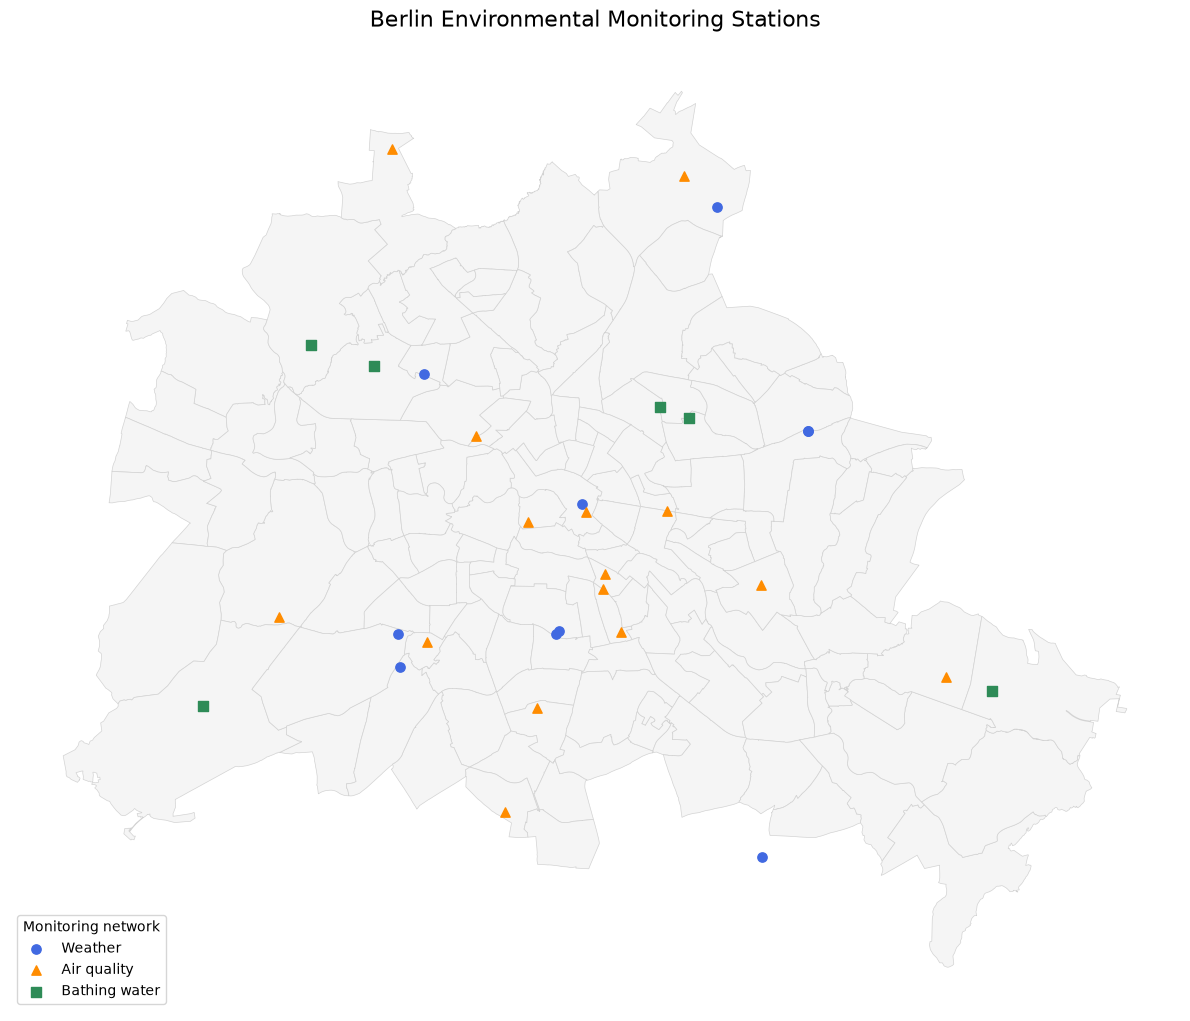

In [41]:
#plotting the map with all stations

import matplotlib.pyplot as plt

# Create the figure
fig, ax = plt.subplots(figsize=(12, 12))

# Plot LOR boundaries
lor_gdf.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="lightgrey",
    linewidth=0.5
)

# Plot weather stations
stations_gdf[
    stations_gdf["station_type"] == "Weather"
].plot(
    ax=ax,
    color="royalblue",
    markersize=45,
    marker="o",
    label="Weather"
)

# Plot air-quality stations
stations_gdf[
    stations_gdf["source"] == "Berlin Air Quality"
].plot(
    ax=ax,
    color="darkorange",
    markersize=45,
    marker="^",
    label="Air quality"
)

# Plot bathing-water stations
stations_gdf[
    stations_gdf["source"] == "Berlin Water Quality"
].plot(
    ax=ax,
    color="seagreen",
    markersize=55,
    marker="s",
    label="Bathing water"
)

# Add title and legend
ax.set_title(
    "Berlin Environmental Monitoring Stations",
    fontsize=16,
    pad=15
)

ax.legend(title="Monitoring network", loc="lower left")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
# Assign the confirmed Dahlem coordinates to both sources, as there were two stations shown
weather_stations.loc[
    weather_stations["station"] == "Dahlem",
    ["latitude", "longitude"]
] = [52.4537, 13.3017]

# Rebuild the combined station table
weather_stations_clean = weather_stations[
    ["station", "source", "station_type", "latitude", "longitude"]
].copy()

all_stations = pd.concat(
    [
        weather_stations_clean,
        air_stations_clean,
        water_stations_clean
    ],
    ignore_index=True
)

# Rebuild the geographic station dataset
stations_gdf = gpd.GeoDataFrame(
    all_stations,
    geometry=gpd.points_from_xy(
        all_stations["longitude"],
        all_stations["latitude"]
    ),
    crs="EPSG:4326"
)

# Check Dahlem and Tempelhof
print(
    weather_stations[
        weather_stations["station"].isin(["Dahlem", "Tempelhof"])
    ].to_string(index=False)
)

  station    source  latitude  longitude station_type
   Dahlem       DWD   52.4537    13.3017      Weather
Tempelhof       DWD   52.4676    13.4020      Weather
   Dahlem Meteostat   52.4537    13.3017      Weather
Tempelhof Meteostat   52.4667    13.4000      Weather
  station    source  latitude  longitude station_type
   Dahlem       DWD   52.4537    13.3017      Weather
Tempelhof       DWD   52.4675    13.4021      Weather
   Dahlem Meteostat   52.4537    13.3017      Weather
Tempelhof Meteostat   52.4667    13.4000      Weather


In [ ]:
# Update DWD Tempelhof to the confirmed coordinates as two stations were shown
weather_stations.loc[
    (weather_stations["station"] == "Tempelhof") &
    (weather_stations["source"] == "DWD"),
    ["latitude", "longitude"]
] = [52.4675, 13.4021]

# Verify all four records
print(
    weather_stations[
        weather_stations["station"].isin(["Dahlem", "Tempelhof"])
    ].to_string(index=False)
)

  station    source  latitude  longitude station_type
   Dahlem       DWD   52.4537    13.3017      Weather
Tempelhof       DWD   52.4675    13.4021      Weather
   Dahlem Meteostat   52.4537    13.3017      Weather
Tempelhof Meteostat   52.4667    13.4000      Weather


In [46]:
# Use the confirmed current coordinates for both Tempelhof records
weather_stations.loc[
    weather_stations["station"] == "Tempelhof",
    ["latitude", "longitude"]
] = [52.4675, 13.4021]

# Rebuild the combined station dataset
weather_stations_clean = weather_stations[
    ["station", "source", "station_type", "latitude", "longitude"]
].copy()

all_stations = pd.concat(
    [weather_stations_clean, air_stations_clean, water_stations_clean],
    ignore_index=True
)

# Rebuild the GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    all_stations,
    geometry=gpd.points_from_xy(
        all_stations["longitude"],
        all_stations["latitude"]
    ),
    crs="EPSG:4326"
)

# Verify the updated records
print(
    weather_stations[
        weather_stations["station"].isin(["Dahlem", "Tempelhof"])
    ].to_string(index=False)
)

  station    source  latitude  longitude station_type
   Dahlem       DWD   52.4537    13.3017      Weather
Tempelhof       DWD   52.4675    13.4021      Weather
   Dahlem Meteostat   52.4537    13.3017      Weather
Tempelhof Meteostat   52.4675    13.4021      Weather


In [47]:
# Count monitoring records and unique geographical locations
print("Monitoring records:", len(stations_gdf))

print(
    "Unique coordinate locations:",
    stations_gdf[["latitude", "longitude"]].drop_duplicates().shape[0]
)

# Show locations shared by multiple records
shared_locations = stations_gdf[
    stations_gdf.duplicated(
        subset=["latitude", "longitude"],
        keep=False
    )
].sort_values(["latitude", "longitude"])

print("\nShared coordinates:")
print(
    shared_locations[
        ["station", "source", "latitude", "longitude"]
    ].to_string(index=False)
)

Monitoring records: 31
Unique coordinate locations: 28

Shared coordinates:
  station    source  latitude  longitude
   Dahlem       DWD   52.4537    13.3017
   Dahlem Meteostat   52.4537    13.3017
Tempelhof       DWD   52.4675    13.4021
Tempelhof Meteostat   52.4675    13.4021
  Marzahn       DWD   52.5447    13.5598
  Marzahn Meteostat   52.5447    13.5598


In [48]:
# Separate weather stations by source
dwd_stations = stations_gdf[
    (stations_gdf["station_type"] == "Weather") &
    (stations_gdf["source"] == "DWD")
].copy()

meteostat_stations = stations_gdf[
    (stations_gdf["station_type"] == "Weather") &
    (stations_gdf["source"] == "Meteostat")
].copy()

# Identify weather locations shared by both sources
shared_coords = (
    dwd_stations[["latitude", "longitude"]]
    .merge(
        meteostat_stations[["latitude", "longitude"]],
        on=["latitude", "longitude"]
    )
    .drop_duplicates()
)

print("Shared weather locations:", len(shared_coords))
print(shared_coords)

Shared weather locations: 3
   latitude  longitude
0   52.4537    13.3017
1   52.5447    13.5598
2   52.4675    13.4021


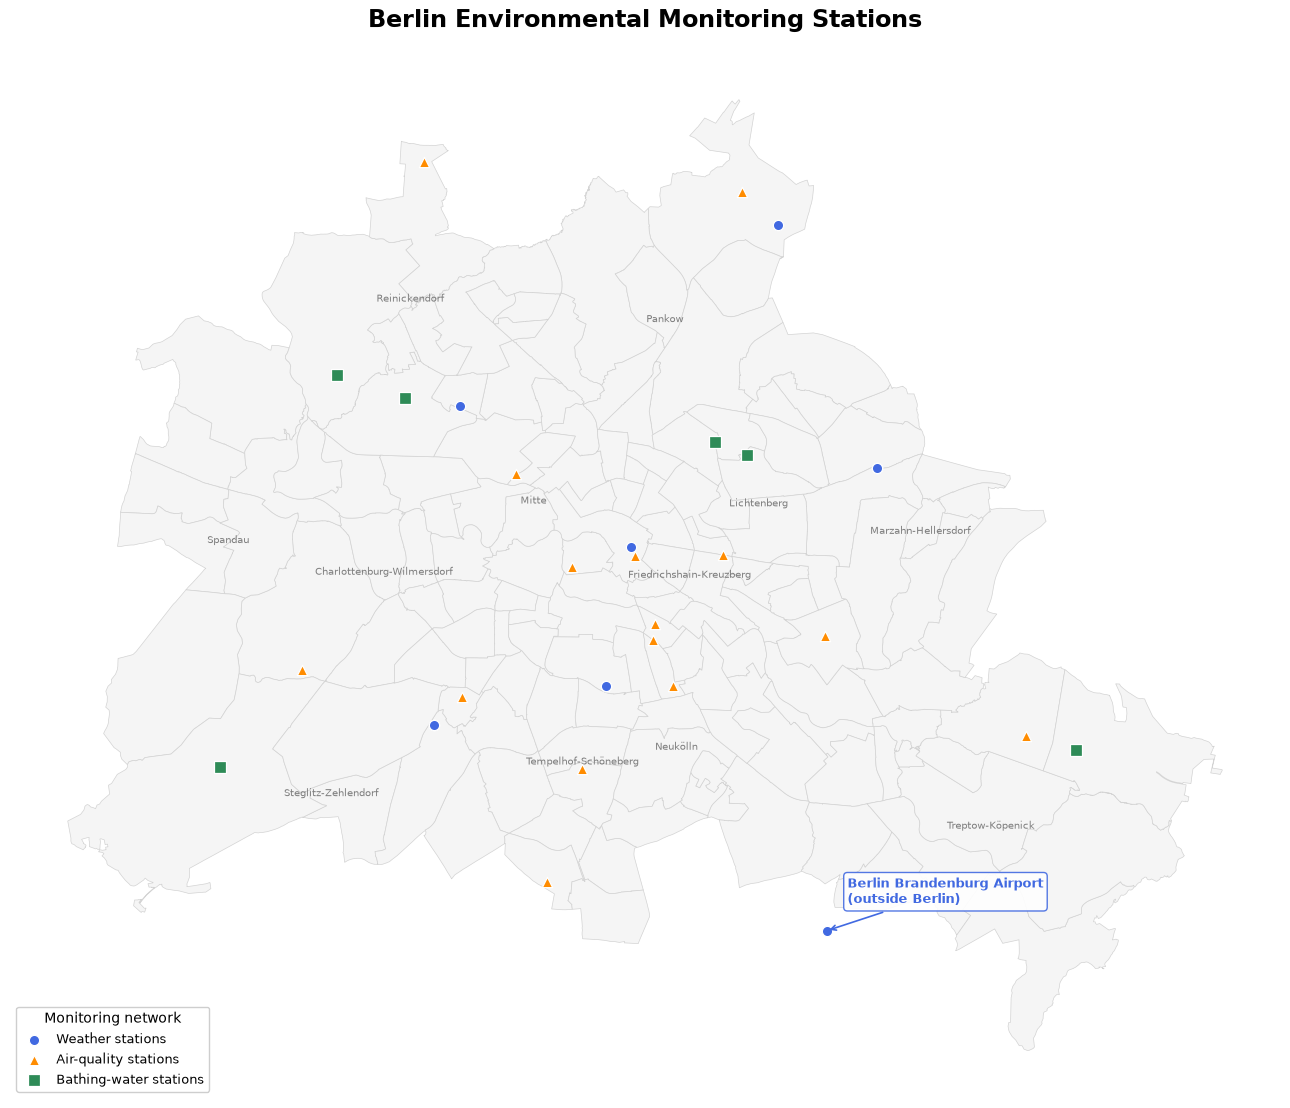

In [51]:
import matplotlib.pyplot as plt

# Create the figure
fig, ax = plt.subplots(figsize=(13, 13))

# Plot LOR boundaries
lor_gdf.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="lightgrey",
    linewidth=0.5
)

# Plot all weather stations with the same symbol
stations_gdf[
    stations_gdf["station_type"] == "Weather"
].plot(
    ax=ax,
    color="royalblue",
    markersize=55,
    marker="o",
    edgecolor="white",
    linewidth=0.9,
    label="Weather stations",
    zorder=3
)

# Plot air-quality stations
stations_gdf[
    stations_gdf["source"] == "Berlin Air Quality"
].plot(
    ax=ax,
    color="darkorange",
    markersize=55,
    marker="^",
    edgecolor="white",
    linewidth=0.9,
    label="Air-quality stations",
    zorder=3
)

# Plot bathing-water stations
stations_gdf[
    stations_gdf["source"] == "Berlin Water Quality"
].plot(
    ax=ax,
    color="seagreen",
    markersize=65,
    marker="s",
    edgecolor="white",
    linewidth=0.9,
    label="Bathing-water stations",
    zorder=3
)

# Create district boundaries and representative label positions
districts = lor_gdf.dissolve(by="bez")
district_labels = districts.copy()
district_labels["geometry"] = districts.geometry.representative_point()

# Add district names without their numeric codes
for district, row in district_labels.iterrows():
    district_name = district.split(" - ", 1)[-1]

    ax.annotate(
        district_name,
        xy=(row.geometry.x, row.geometry.y),
        ha="center",
        va="center",
        fontsize=7,
        color="dimgray",
        alpha=0.85,
        zorder=2
    )

# Highlight Berlin Brandenburg Airport weather station
airport = stations_gdf[
    stations_gdf["station"] == "Berlin Brandenburg"
].iloc[0]

ax.annotate(
    "Berlin Brandenburg Airport\n(outside Berlin)",
    xy=(airport.geometry.x, airport.geometry.y),
    xytext=(15, 20),
    textcoords="offset points",
    fontsize=9,
    color="royalblue",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="royalblue",
        lw=1.2
    ),
    bbox=dict(
        boxstyle="round,pad=0.3",
        fc="white",
        ec="royalblue",
        alpha=0.9
    ),
    zorder=5
)

# Add title and legend
ax.set_title(
    "Berlin Environmental Monitoring Stations",
    fontsize=17,
    pad=18,
    fontweight="bold"
)

ax.legend(
    title="Monitoring network",
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    fontsize=9
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [52]:
# Reproject station locations to a coordinate system measured in metres
stations_metric = stations_gdf.to_crs("EPSG:25833")

# Select unique weather station locations
weather_points = stations_metric[
    stations_metric["station_type"] == "Weather"
].drop_duplicates(
    subset=["latitude", "longitude"]
).copy()

# Select air-quality stations
air_points = stations_metric[
    stations_metric["source"] == "Berlin Air Quality"
].copy()

# Create 1 km buffers around weather stations
weather_buffers = gpd.GeoDataFrame(
    weather_points[["station", "source"]].copy(),
    geometry=weather_points.geometry.buffer(1000),
    crs="EPSG:25833"
)

# Create 1 km buffers around air-quality stations
air_buffers = gpd.GeoDataFrame(
    air_points[["station", "source"]].copy(),
    geometry=air_points.geometry.buffer(1000),
    crs="EPSG:25833"
)

# Convert buffers back to the map coordinate system
weather_buffers = weather_buffers.to_crs("EPSG:4326")
air_buffers = air_buffers.to_crs("EPSG:4326")

# Check the results
print("Weather buffers:", len(weather_buffers))
print("Air-quality buffers:", len(air_buffers))
print("Buffer radius: 1,000 metres")

Weather buffers: 7
Air-quality buffers: 15
Buffer radius: 1,000 metres


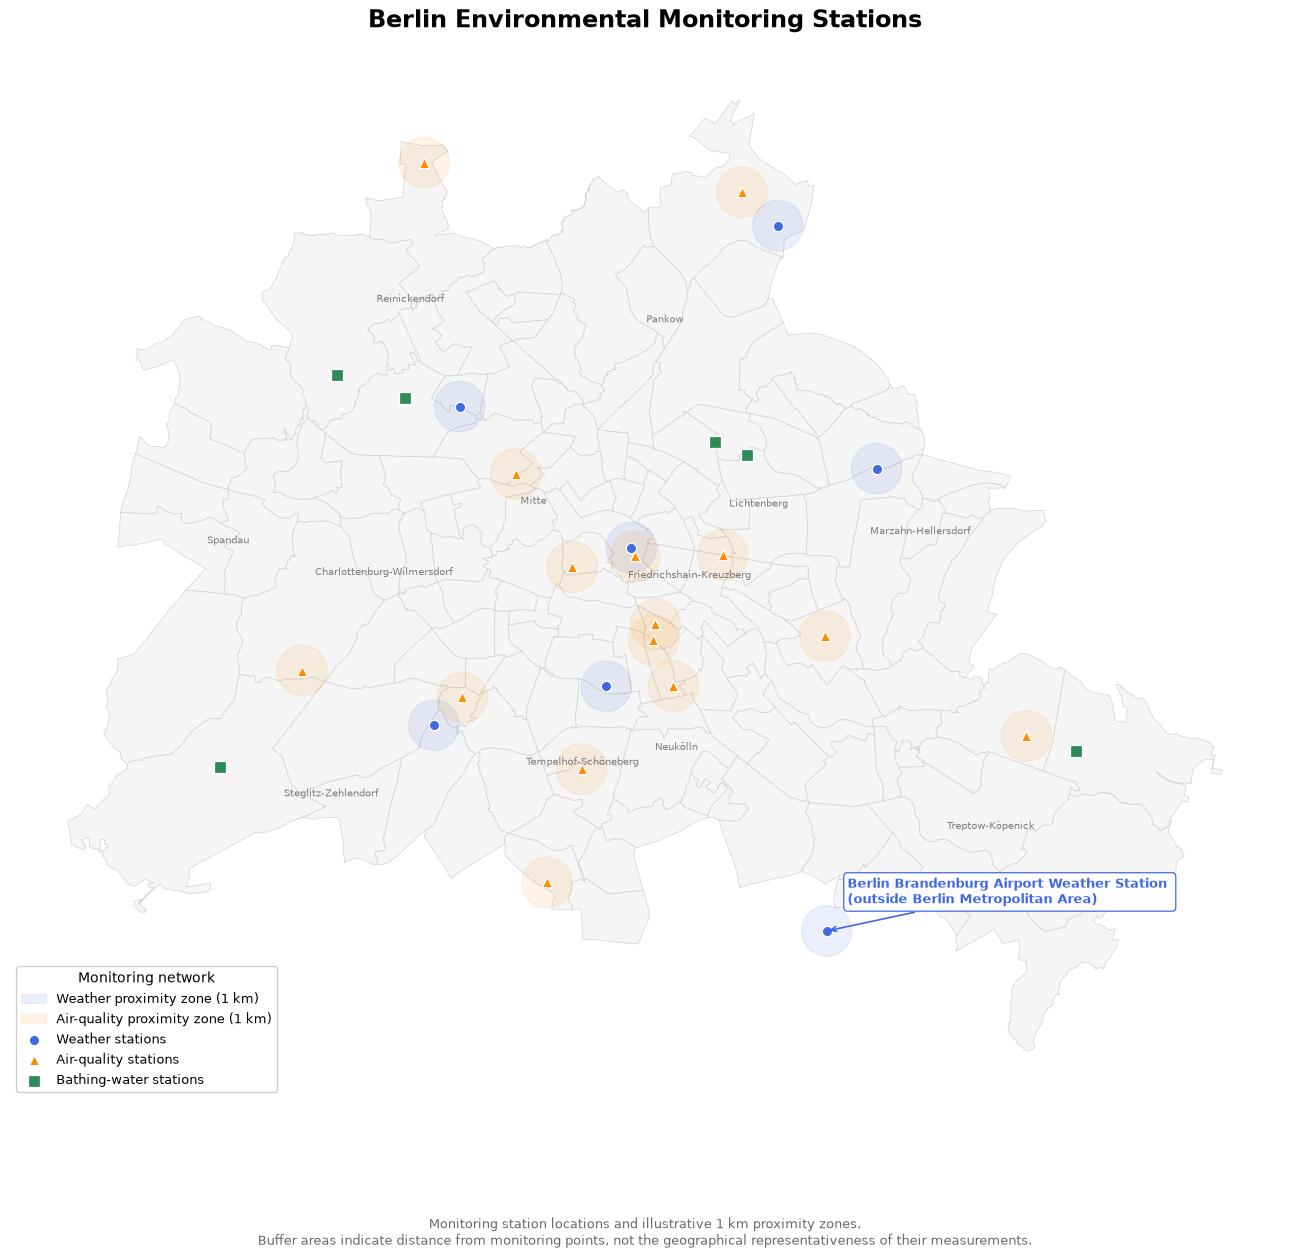

In [76]:
# Create the figure
fig, ax = plt.subplots(figsize=(13, 13))

# Plot LOR boundaries
lor_gdf.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="lightgrey",
    linewidth=0.5
)

# Plot weather proximity zones
weather_buffers.plot(
    ax=ax,
    facecolor="royalblue",
    edgecolor="royalblue",
    alpha=0.10,
    linewidth=0.8,
    label="Weather proximity zone (1 km)",
    zorder=1
)

# Plot air-quality proximity zones
air_buffers.plot(
    ax=ax,
    facecolor="darkorange",
    edgecolor="darkorange",
    alpha=0.10,
    linewidth=0.8,
    label="Air-quality proximity zone (1 km)",
    zorder=1
)

# Plot weather stations
stations_gdf[
    stations_gdf["station_type"] == "Weather"
].plot(
    ax=ax,
    color="royalblue",
    markersize=55,
    marker="o",
    edgecolor="white",
    linewidth=0.9,
    label="Weather stations",
    zorder=3
)

# Plot air-quality stations
stations_gdf[
    stations_gdf["source"] == "Berlin Air Quality"
].plot(
    ax=ax,
    color="darkorange",
    markersize=55,
    marker="^",
    edgecolor="white",
    linewidth=0.9,
    label="Air-quality stations",
    zorder=3
)

# Plot bathing-water stations
stations_gdf[
    stations_gdf["source"] == "Berlin Water Quality"
].plot(
    ax=ax,
    color="seagreen",
    markersize=65,
    marker="s",
    edgecolor="white",
    linewidth=0.9,
    label="Bathing-water stations",
    zorder=3
)

# Create district boundaries and representative label positions
districts = lor_gdf.dissolve(by="bez")
district_labels = districts.copy()
district_labels["geometry"] = districts.geometry.representative_point()

# Add district names
for district, row in district_labels.iterrows():
    district_name = district.split(" - ", 1)[-1]

    ax.annotate(
        district_name,
        xy=(row.geometry.x, row.geometry.y),
        ha="center",
        va="center",
        fontsize=7,
        color="dimgray",
        alpha=0.85,
        zorder=2
    )

# Highlight Berlin Brandenburg Airport
airport = stations_gdf[
    stations_gdf["station"] == "Berlin Brandenburg"
].iloc[0]

ax.annotate(
    "Berlin Brandenburg Airport Weather Station \n(outside Berlin Metropolitan Area)",
    xy=(airport.geometry.x, airport.geometry.y),
    xytext=(15, 20),
    textcoords="offset points",
    fontsize=9,
    color="royalblue",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="royalblue",
        lw=1.2
    ),
    bbox=dict(
        boxstyle="round,pad=0.3",
        fc="white",
        ec="royalblue",
        alpha=0.9
    ),
    zorder=5
)

# Add title
ax.set_title(
    "Berlin Environmental Monitoring Stations",
    fontsize=17,
    pad=18,
    fontweight="bold"
)

# Add legend
ax.legend(
    title="Monitoring network",
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    fontsize=9
)

ax.set_axis_off()

# Add explanatory caption below the map
fig.text(
    0.5, 0.015,
    "Monitoring station locations and illustrative 1 km proximity zones.\n"
    "Buffer areas indicate distance from monitoring points, not the geographical representativeness of their measurements.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

# Leave space for the caption
plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()

Maximum advised radius for weather stations in compact urban areas is around 500 metres, so probably will change this.

Source: https://scispace.com/pdf/local-climate-zones-for-urban-temperature-studies-4oy0c779bb.pdf

In [55]:
# Check the available raster and buffer objects
print("Weather buffers:")
print(weather_buffers.crs, weather_buffers.shape)

print("\nAir-quality buffers:")
print(air_buffers.crs, air_buffers.shape)

print("\nAvailable raster variables:")
for name in [
    "imperviousness",
    "imperviousness_raster",
    "tree_cover",
    "tree_cover_raster"
]:
    if name in globals():
        print(name, type(globals()[name]))

Weather buffers:
EPSG:4326 (7, 3)

Air-quality buffers:
EPSG:4326 (15, 3)

Available raster variables:


In [ ]:
# Check the contents of the data directory, to find the satellite data for tree coverage and imperviousness
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for file in files:
        if file.lower().endswith((".tif", ".tiff", ".vrt")):
            print(os.path.join(root, file))

.\satellite_data\imperv_berlin_2024.tif
.\satellite_data\tree_density_2024.tif


In [61]:
import rasterio

# Define raster file paths
imperv_path = "satellite_data/imperv_berlin_2024.tif"
tree_path = "satellite_data/tree_density_2024.tif"

# Inspect imperviousness raster
with rasterio.open(imperv_path) as src:
    print("IMPERviousness raster")
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("NoData:", src.nodata)
    print("Bounds:", src.bounds)

# Inspect tree-cover raster
with rasterio.open(tree_path) as src:
    print("\nTREE-COVER raster")
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("NoData:", src.nodata)
    print("Bounds:", src.bounds)

IMPERviousness raster
CRS: EPSG:3035
Resolution: (10.0, 10.0)
Dimensions: 10000 x 10000
NoData: None
Bounds: BoundingBox(left=4500000.0, bottom=3200000.0, right=4600000.0, top=3300000.0)

TREE-COVER raster
CRS: PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARAMETER["latitude_of_center",52],PARAMETER["longitude_of_center",10],PARAMETER["false_easting",4321000],PARAMETER["false_northing",3210000],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3035"]]
Resolution: (9.999999996455808, 10.000000003544207)
Dimensions: 4550 x 3662
NoData: None
Bounds: BoundingBox(left=4531079.999999999, bottom=3254009.999987033, right=4576579.999983873, top=3290630.000000012)


In [62]:
# Reproject station buffers to the raster CRS
weather_buffers_3035 = weather_buffers.to_crs("EPSG:3035")
air_buffers_3035 = air_buffers.to_crs("EPSG:3035")

# Check CRS and geometry validity
print("Weather buffers CRS:", weather_buffers_3035.crs)
print("Air-quality buffers CRS:", air_buffers_3035.crs)

print("\nWeather buffer geometries valid:",
      weather_buffers_3035.geometry.is_valid.all())

print("Air-quality buffer geometries valid:",
      air_buffers_3035.geometry.is_valid.all())

Weather buffers CRS: EPSG:3035
Air-quality buffers CRS: EPSG:3035

Weather buffer geometries valid: True
Air-quality buffer geometries valid: True


In [63]:
import rasterio
import numpy as np
from rasterio.mask import mask

# Extract imperviousness statistics for each buffer
def extract_raster_stats(buffers_gdf, raster_path):

    results = []

    with rasterio.open(raster_path) as src:

        for idx, row in buffers_gdf.iterrows():

            # Extract raster pixels within the buffer
            out_image, out_transform = mask(
                src,
                [row.geometry],
                crop=True,
                filled=False,
                all_touched=False
            )

            # Convert extracted pixels to a one-dimensional array
            pixels = out_image[0].compressed()

            # Store summary statistics
            results.append({
                "buffer_index": idx,
                "mean": pixels.mean() if len(pixels) > 0 else np.nan,
                "median": np.median(pixels) if len(pixels) > 0 else np.nan,
                "pixel_count": len(pixels)
            })

    return pd.DataFrame(results)


# Extract imperviousness for weather and air-quality buffers
weather_imperv_stats = extract_raster_stats(
    weather_buffers_3035,
    imperv_path
)

air_imperv_stats = extract_raster_stats(
    air_buffers_3035,
    imperv_path
)

print("Weather buffers:")
display(weather_imperv_stats)

print("\nAir-quality buffers:")
display(air_imperv_stats)

Weather buffers:


,buffer_index,mean,median,pixel_count
0,0,23.063424,0.0,31376
1,1,29.669533,0.0,31395
2,2,36.736079,42.0,31373
3,3,46.119263,54.0,31376
4,4,33.209745,0.0,31381
5,5,70.350497,89.0,31384
6,8,48.448687,59.0,31376



Air-quality buffers:


,buffer_index,mean,median,pixel_count
0,10,68.782778,85.0,31378
1,11,15.566959,0.0,31385
2,12,1.759700,0.0,31365
3,13,66.946206,84.0,31379
4,14,7.990761,0.0,31390
5,15,8.772549,0.0,31387
6,16,58.895118,70.0,31378
7,17,46.434839,56.0,31384
8,18,68.684481,83.0,31380
9,19,4.640822,0.0,31380


In [64]:
# Extract tree-cover statistics for each buffer
weather_tree_stats = extract_raster_stats(
    weather_buffers_3035,
    tree_path
)

air_tree_stats = extract_raster_stats(
    air_buffers_3035,
    tree_path
)

print("Weather buffers:")
display(weather_tree_stats)

print("\nAir-quality buffers:")
display(air_tree_stats)

Weather buffers:


,buffer_index,mean,median,pixel_count
0,0,0.000000,0.0,31376
1,1,29.073228,0.0,31395
2,2,17.647468,0.0,31373
3,3,6.926281,0.0,31376
4,4,3.042733,0.0,31381
5,5,5.494870,0.0,31384
6,8,7.379494,0.0,31376



Air-quality buffers:


,buffer_index,mean,median,pixel_count
0,10,8.061444,0.0,31378
1,11,14.055345,0.0,31385
2,12,80.794261,93.0,31365
3,13,7.728321,0.0,31379
4,14,67.079165,95.0,31390
5,15,33.748781,0.0,31387
6,16,7.631908,0.0,31378
7,17,15.097534,0.0,31384
8,18,8.112779,0.0,31380
9,19,62.582983,94.0,31380


In [65]:
# Inspect buffer attributes and their original station records
print("Weather buffer columns:")
print(weather_buffers.columns.tolist())

print("\nWeather station records:")
display(
    stations_gdf.loc[
        weather_buffers.index,
        ["station", "source", "station_type", "latitude", "longitude"]
    ]
)

print("\nAir-quality station records:")
display(
    stations_gdf.loc[
        air_buffers.index,
        ["station", "source", "station_type", "latitude", "longitude"]
    ]
)

Weather buffer columns:
['station', 'source', 'geometry']

Weather station records:


,station,source,station_type,latitude,longitude
0,Berlin Brandenburg,DWD,Weather,52.3807,13.5306
1,Buch,DWD,Weather,52.6309,13.5022
2,Dahlem,DWD,Weather,52.4537,13.3017
3,Marzahn,DWD,Weather,52.5447,13.5598
4,Tempelhof,DWD,Weather,52.4675,13.4021
5,Alexanderplatz,Meteostat,Weather,52.5167,13.4167
8,Tegel,Meteostat,Weather,52.5667,13.3167



Air-quality station records:


,station,source,station_type,latitude,longitude
10,mc010,Berlin Air Quality,Urban background,52.542855,13.349353
11,mc027,Berlin Air Quality,Outskirts,52.397909,13.367526
12,mc032,Berlin Air Quality,Outskirts,52.473080,13.224957
13,mc042,Berlin Air Quality,Urban background,52.489442,13.430847
14,mc077,Berlin Air Quality,Outskirts,52.642739,13.481295
15,mc085,Berlin Air Quality,Outskirts,52.449899,13.646985
16,mc117,Berlin Air Quality,Traffic,52.463600,13.318226
17,mc124,Berlin Air Quality,Traffic,52.438125,13.387755
18,mc144,Berlin Air Quality,Traffic,52.467461,13.441213
19,mc145,Berlin Air Quality,Outskirts,52.653270,13.296080


In [66]:
# Combine raster statistics with station metadata
def combine_station_stats(buffers_gdf, imperv_stats, tree_stats, station_type=None):

    # Set original buffer indices as the index for joining
    imperv = imperv_stats.set_index("buffer_index")
    tree = tree_stats.set_index("buffer_index")

    # Combine imperviousness and tree-cover statistics
    raster_stats = pd.DataFrame({
        "imperv_mean": imperv["mean"],
        "imperv_median": imperv["median"],
        "tree_mean": tree["mean"],
        "tree_median": tree["median"],
        "imperv_pixel_count": imperv["pixel_count"],
        "tree_pixel_count": tree["pixel_count"]
    })

    # Retrieve station metadata using the original buffer indices
    station_info = stations_gdf.loc[
        buffers_gdf.index,
        ["station", "source"]
    ].copy()

    if station_type:
        station_info["station_type"] = station_type

    # Join station metadata with raster statistics
    return station_info.join(raster_stats)


# Create weather station table
weather_station_context = combine_station_stats(
    weather_buffers,
    weather_imperv_stats,
    weather_tree_stats,
    station_type="Weather"
)

# Create air-quality station table
air_station_context = combine_station_stats(
    air_buffers,
    air_imperv_stats,
    air_tree_stats
)

print("Weather station context:")
display(weather_station_context.round(2))

print("\nAir-quality station context:")
display(air_station_context.round(2))

Weather station context:


,station,source,station_type,imperv_mean,imperv_median,tree_mean,tree_median,imperv_pixel_count,tree_pixel_count
0,Berlin Brandenburg,DWD,Weather,23.06,0.0,0.00,0.0,31376,31376
1,Buch,DWD,Weather,29.67,0.0,29.07,0.0,31395,31395
2,Dahlem,DWD,Weather,36.74,42.0,17.65,0.0,31373,31373
3,Marzahn,DWD,Weather,46.12,54.0,6.93,0.0,31376,31376
4,Tempelhof,DWD,Weather,33.21,0.0,3.04,0.0,31381,31381
5,Alexanderplatz,Meteostat,Weather,70.35,89.0,5.49,0.0,31384,31384
8,Tegel,Meteostat,Weather,48.45,59.0,7.38,0.0,31376,31376



Air-quality station context:


,station,source,imperv_mean,imperv_median,tree_mean,tree_median,imperv_pixel_count,tree_pixel_count
10,mc010,Berlin Air Quality,68.78,85.0,8.06,0.0,31378,31378
11,mc027,Berlin Air Quality,15.57,0.0,14.06,0.0,31385,31385
12,mc032,Berlin Air Quality,1.76,0.0,80.79,93.0,31365,31365
13,mc042,Berlin Air Quality,66.95,84.0,7.73,0.0,31379,31379
14,mc077,Berlin Air Quality,7.99,0.0,67.08,95.0,31390,31390
15,mc085,Berlin Air Quality,8.77,0.0,33.75,0.0,31387,31387
16,mc117,Berlin Air Quality,58.90,70.0,7.63,0.0,31378,31378
17,mc124,Berlin Air Quality,46.43,56.0,15.10,0.0,31384,31384
18,mc144,Berlin Air Quality,68.68,83.0,8.11,0.0,31380,31380
19,mc145,Berlin Air Quality,4.64,0.0,62.58,94.0,31380,31380


In [67]:
# Add station classifications and coordinates
for df in [weather_station_context, air_station_context]:

    df[["station_type", "latitude", "longitude"]] = (
        stations_gdf.loc[
            df.index,
            ["station_type", "latitude", "longitude"]
        ]
    )

# Display the enriched air-quality table
display(
    air_station_context[
        [
            "station",
            "station_type",
            "latitude",
            "longitude",
            "imperv_mean",
            "tree_mean"
        ]
    ].round(2)
)

,station,station_type,latitude,longitude,imperv_mean,tree_mean
10,mc010,Urban background,52.54,13.35,68.78,8.06
11,mc027,Outskirts,52.40,13.37,15.57,14.06
12,mc032,Outskirts,52.47,13.22,1.76,80.79
13,mc042,Urban background,52.49,13.43,66.95,7.73
14,mc077,Outskirts,52.64,13.48,7.99,67.08
15,mc085,Outskirts,52.45,13.65,8.77,33.75
16,mc117,Traffic,52.46,13.32,58.90,7.63
17,mc124,Traffic,52.44,13.39,46.43,15.10
18,mc144,Traffic,52.47,13.44,68.68,8.11
19,mc145,Outskirts,52.65,13.30,4.64,62.58


In [68]:
# Inspect the weather dataset before aggregation
print("Columns:")
print(weather_all_df.columns.tolist())

print("\nStation and source combinations:")
display(
    weather_all_df[
        ["station", "source"]
    ].drop_duplicates().sort_values(
        ["source", "station"]
    )
)

print("\nDate range:")
print(weather_all_df["date"].min())
print(weather_all_df["date"].max())

Columns:
['Unnamed: 0', 'station_id', 'date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'tsun', 'cloud_cover', 'pres_dwd', 'station', 'source', 'pres_meteostat']

Station and source combinations:


,station,source
0,Berlin Brandenburg,DWD
550,Buch,DWD
1100,Dahlem,DWD
1650,Marzahn,DWD
2200,Tempelhof,DWD
2750,Alexanderplatz,Meteostat
3053,Dahlem,Meteostat
3356,Marzahn,Meteostat
3659,Tegel,Meteostat
3962,Tempelhof,Meteostat



Date range:
2025-01-01 00:00:00
2026-10-30 00:00:00


In [69]:
# Ensure date is in datetime format
weather_all_df["date"] = pd.to_datetime(weather_all_df["date"])

# Filter summer observations
summer_weather = weather_all_df[
    weather_all_df["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Calculate summer indicators per station and year
weather_summer_stats = (
    summer_weather
    .groupby(["station", "source", summer_weather["date"].dt.year])
    .agg(
        mean_tmax=("tmax", "mean"),
        mean_tavg=("tavg", "mean"),
        hot_days=("tmax", lambda x: (x >= 30).sum()),
        extreme_days=("tmax", lambda x: (x >= 35).sum()),
        valid_tmax_days=("tmax", "count")
    )
    .reset_index()
    .rename(columns={"date": "year"})
)

display(weather_summer_stats.round(2))

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days
0,Alexanderplatz,Meteostat,2025,22.44,17.97,6,1,122
1,Alexanderplatz,Meteostat,2026,23.42,18.76,13,3,122
2,Berlin Brandenburg,DWD,2025,23.94,18.35,11,1,122
3,Berlin Brandenburg,DWD,2026,25.10,19.07,18,5,122
4,Buch,DWD,2025,23.71,17.79,9,1,122
5,Buch,DWD,2026,24.82,18.53,20,4,122
6,Dahlem,DWD,2025,23.81,18.08,9,1,122
7,Dahlem,DWD,2026,24.51,18.65,15,3,122
8,Dahlem,Meteostat,2026,24.51,18.65,15,3,122
9,Marzahn,DWD,2025,24.14,18.68,10,2,122


In [70]:
# Check how much of each 1 km buffer is covered by each raster

from shapely.geometry import box

def check_raster_coverage(buffers_gdf, raster_path, raster_name):
    results = []

    with rasterio.open(raster_path) as src:
        raster_extent = box(*src.bounds)

        for idx, row in buffers_gdf.iterrows():
            buffer_geometry = row.geometry

            intersection = buffer_geometry.intersection(raster_extent)

            coverage_pct = (
                intersection.area / buffer_geometry.area
            ) * 100

            results.append({
                "buffer_index": idx,
                f"{raster_name}_coverage_pct": coverage_pct
            })

    return pd.DataFrame(results)


# Check weather buffers against both rasters
weather_imperv_coverage = check_raster_coverage(
    weather_buffers_3035,
    imperv_path,
    "imperv"
)

weather_tree_coverage = check_raster_coverage(
    weather_buffers_3035,
    tree_path,
    "tree"
)

# Combine coverage results
weather_coverage = (
    weather_imperv_coverage
    .merge(weather_tree_coverage, on="buffer_index")
)

display(weather_coverage.round(2))

,buffer_index,imperv_coverage_pct,tree_coverage_pct
0,0,100.0,100.0
1,1,100.0,100.0
2,2,100.0,100.0
3,3,100.0,100.0
4,4,100.0,100.0
5,5,100.0,100.0
6,8,100.0,100.0


In [71]:
# Select one source per physical weather-station location
preferred_sources = {
    "Berlin Brandenburg": "DWD",
    "Buch": "DWD",
    "Dahlem": "DWD",
    "Marzahn": "DWD",
    "Tempelhof": "DWD",
    "Alexanderplatz": "Meteostat",
    "Tegel": "Meteostat"
}

weather_selected = weather_summer_stats[
    weather_summer_stats.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Join summer weather indicators with the station surroundings
weather_environment = weather_selected.merge(
    weather_station_context[
        ["station", "imperv_mean", "tree_mean"]
    ],
    on="station",
    how="left"
)

# Display the combined dataset
display(
    weather_environment
    .sort_values(["year", "station"])
    .round(2)
)

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days,imperv_mean,tree_mean
0,Alexanderplatz,Meteostat,2025,22.44,17.97,6,1,122,70.35,5.49
2,Berlin Brandenburg,DWD,2025,23.94,18.35,11,1,122,23.06,0.00
4,Buch,DWD,2025,23.71,17.79,9,1,122,29.67,29.07
6,Dahlem,DWD,2025,23.81,18.08,9,1,122,36.74,17.65
8,Marzahn,DWD,2025,24.14,18.68,10,2,122,46.12,6.93
10,Tegel,Meteostat,2025,22.36,17.84,6,1,122,48.45,7.38
12,Tempelhof,DWD,2025,24.20,18.73,11,1,122,33.21,3.04
1,Alexanderplatz,Meteostat,2026,23.42,18.76,13,3,122,70.35,5.49
3,Berlin Brandenburg,DWD,2026,25.10,19.07,18,5,122,23.06,0.00
5,Buch,DWD,2026,24.82,18.53,20,4,122,29.67,29.07


In [72]:
from scipy.stats import spearmanr

# Variables to compare
temperature_metrics = [
    "mean_tmax",
    "mean_tavg",
    "hot_days"
]

environment_metrics = [
    "imperv_mean",
    "tree_mean"
]

correlation_results = []

# Calculate correlations separately for each summer
for year in sorted(weather_environment["year"].unique()):

    year_data = weather_environment[
        weather_environment["year"] == year
    ]

    for temperature in temperature_metrics:
        for environment in environment_metrics:

            rho, p_value = spearmanr(
                year_data[environment],
                year_data[temperature]
            )

            correlation_results.append({
                "year": year,
                "temperature_metric": temperature,
                "environment_metric": environment,
                "spearman_rho": rho,
                "p_value": p_value,
                "n_stations": len(year_data)
            })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(3))

,year,temperature_metric,environment_metric,spearman_rho,p_value,n_stations
0,2025,mean_tmax,imperv_mean,-0.500,0.253,7
1,2025,mean_tmax,tree_mean,-0.464,0.294,7
2,2025,mean_tavg,imperv_mean,-0.179,0.702,7
3,2025,mean_tavg,tree_mean,-0.679,0.094,7
4,2025,hot_days,imperv_mean,-0.753,0.051,7
5,2025,hot_days,tree_mean,-0.551,0.200,7
6,2026,mean_tmax,imperv_mean,-0.714,0.071,7
7,2026,mean_tmax,tree_mean,-0.536,0.215,7
8,2026,mean_tavg,imperv_mean,-0.071,0.879,7
9,2026,mean_tavg,tree_mean,-0.786,0.036,7


Correlations between imperviousness and temperature are negative in both years as the seven stations with higher surrounding imperviousness tended to have lower recorded temperatures in this particular comparison.

That does not support a simple claim that more impervious surroundings correspond to higher temperatures. It also does not demonstrate that imperviousness reduces temperature.

In [73]:
# Inspect station-level temperature and environmental context
station_comparison = weather_environment[
    [
        "year",
        "station",
        "source",
        "mean_tmax",
        "mean_tavg",
        "hot_days",
        "extreme_days",
        "imperv_mean",
        "tree_mean"
    ]
].copy()

for year in sorted(station_comparison["year"].unique()):
    print(f"\nSummer {year} — stations ranked by mean maximum temperature")

    display(
        station_comparison[
            station_comparison["year"] == year
        ]
        .sort_values("mean_tmax", ascending=False)
        .round(2)
        .reset_index(drop=True)
    )


Summer 2025 — stations ranked by mean maximum temperature


,year,station,source,mean_tmax,mean_tavg,hot_days,extreme_days,imperv_mean,tree_mean
0,2025,Tempelhof,DWD,24.20,18.73,11,1,33.21,3.04
1,2025,Marzahn,DWD,24.14,18.68,10,2,46.12,6.93
2,2025,Berlin Brandenburg,DWD,23.94,18.35,11,1,23.06,0.00
3,2025,Dahlem,DWD,23.81,18.08,9,1,36.74,17.65
4,2025,Buch,DWD,23.71,17.79,9,1,29.67,29.07
5,2025,Alexanderplatz,Meteostat,22.44,17.97,6,1,70.35,5.49
6,2025,Tegel,Meteostat,22.36,17.84,6,1,48.45,7.38



Summer 2026 — stations ranked by mean maximum temperature


,year,station,source,mean_tmax,mean_tavg,hot_days,extreme_days,imperv_mean,tree_mean
0,2026,Tempelhof,DWD,25.29,19.48,21,6,33.21,3.04
1,2026,Berlin Brandenburg,DWD,25.10,19.07,18,5,23.06,0.00
2,2026,Marzahn,DWD,25.06,19.34,19,4,46.12,6.93
3,2026,Buch,DWD,24.82,18.53,20,4,29.67,29.07
4,2026,Dahlem,DWD,24.51,18.65,15,3,36.74,17.65
5,2026,Alexanderplatz,Meteostat,23.42,18.76,13,3,70.35,5.49
6,2026,Tegel,Meteostat,23.33,18.63,12,3,48.45,7.38


The station-level tables reveal why the correlations look counterintuitive: Alexanderplatz and Tegel are among the coolest stations in both summers, despite having relatively high imperviousness and low tree cover. They strongly influence the negative correlations.

There is also a source-related distinction: both are Meteostat stations, whereas the other five locations use DWD observations. We should not assume that differences between these sources are responsible, but we should test whether the pattern persists using only the five DWD stations.

In [74]:
# Keep only DWD stations
dwd_data = weather_environment[
    weather_environment["source"] == "DWD"
].copy()

dwd_results = []

# Calculate correlations separately for each year
for year in sorted(dwd_data["year"].unique()):

    year_data = dwd_data[dwd_data["year"] == year]

    for temperature in ["mean_tmax", "mean_tavg", "hot_days"]:
        for environment in ["imperv_mean", "tree_mean"]:

            rho, p_value = spearmanr(
                year_data[environment],
                year_data[temperature]
            )

            dwd_results.append({
                "year": year,
                "temperature_metric": temperature,
                "environment_metric": environment,
                "spearman_rho": rho,
                "p_value": p_value,
                "n_stations": len(year_data)
            })

dwd_correlation_df = pd.DataFrame(dwd_results)

display(dwd_correlation_df.round(3))

,year,temperature_metric,environment_metric,spearman_rho,p_value,n_stations
0,2025,mean_tmax,imperv_mean,0.300,0.624,5
1,2025,mean_tmax,tree_mean,-0.700,0.188,5
2,2025,mean_tavg,imperv_mean,0.300,0.624,5
3,2025,mean_tavg,tree_mean,-0.700,0.188,5
4,2025,hot_days,imperv_mean,-0.316,0.604,5
5,2025,hot_days,tree_mean,-0.949,0.014,5
6,2026,mean_tmax,imperv_mean,-0.300,0.624,5
7,2026,mean_tmax,tree_mean,-0.800,0.104,5
8,2026,mean_tavg,imperv_mean,0.300,0.624,5
9,2026,mean_tavg,tree_mean,-0.700,0.188,5


In [ ]:
# Compare summer temperature indicators between 2025 and 2026

weather_changes = (
    weather_environment
    .pivot(
        index=["station", "source", "imperv_mean", "tree_mean"],
        columns="year",
        values=["mean_tmax", "mean_tavg", "hot_days", "extreme_days"]
    )
)

# Flatten the multi-level column names
weather_changes.columns = [
    f"{metric}_{year}"
    for metric, year in weather_changes.columns
]

weather_changes = weather_changes.reset_index()

# Calculate the change from 2025 to 2026
for metric in ["mean_tmax", "mean_tavg", "hot_days", "extreme_days"]:
    weather_changes[f"change_{metric}"] = (
        weather_changes[f"{metric}_2026"]
        - weather_changes[f"{metric}_2025"]
    )

display(
    weather_changes[
        [
            "station",
            "source",
            "imperv_mean",
            "tree_mean",
            "change_mean_tmax",
            "change_mean_tavg",
            "change_hot_days",
            "change_extreme_days"
        ]
    ]
    .sort_values("change_mean_tmax", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

,station,source,imperv_mean,tree_mean,change_mean_tmax,change_mean_tavg,change_hot_days,change_extreme_days
0,Berlin Brandenburg,DWD,23.06,0.00,1.16,0.73,7.0,4.0
1,Buch,DWD,29.67,29.07,1.11,0.74,11.0,3.0
2,Tempelhof,DWD,33.21,3.04,1.09,0.74,10.0,5.0
3,Alexanderplatz,Meteostat,70.35,5.49,0.99,0.79,7.0,2.0
4,Tegel,Meteostat,48.45,7.38,0.97,0.79,6.0,2.0
5,Marzahn,DWD,46.12,6.93,0.92,0.66,9.0,2.0
6,Dahlem,DWD,36.74,17.65,0.70,0.57,6.0,2.0


Summer 2026 was warmer than summer 2025 across all seven monitoring locations. Mean daily maximum temperatures increased by 0.70–1.16°C, while the number of days reaching at least 30°C increased by 6–11 days per station. The magnitude of change varied across locations, but no consistent relationship with the surrounding 1 km imperviousness or tree-cover averages could be established.